This script uses the ``analysis_functions.py`` functions

In [15]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Import experiment_config2 (sometimes at a level up)
cwd = Path.cwd()
while not (cwd / "experiment_config2.py").exists():
    cwd = cwd.parent
sys.path.insert(0, str(cwd))
from experiment_config3 import Config

# Import color map
cwd = Path.cwd()
while not (cwd / "color_map.py").exists():
    cwd = cwd.parent
sys.path.insert(0, str(cwd))
from color_map import make_color_map


import analysis_functions as af  # import all functions from analysis_functions.py

base_path = Path(
    "J:/sequences/1007_sequences"
)

sequences = Config.from_file(
    base_path
)

print(sequences)


pqif_vector = sequences.pqif_numbers


# color_map_pqif = make_color_map(pqif_vector[1:-1], plt.cm.Greens)
color_map_pqif = {}
color_map_pqif[pqif_vector[0]] = 'black'
color_map_pqif[pqif_vector[1]] = plt.cm.Greens(0.8)
color_map_pqif[pqif_vector[-1]] = 'steelblue'

Config name: 1007_sequences
  target: sequences
  pqif: [0, 0.5, 1]
  simulations: 1: vt=0, vreset=-8.5, 2: vt=0, vreset=-12.3, 3: vt=0, vreset=-17, 4: vt=0, vreset=-22
  seeds: 20
  sequence conditions: 27
  amplitudes: [2.0, 4.0, 6.0]
  sigmas: [10.0, 15.0, 20.0]
  offsets: [0.0, 1.0, 2.0]
  base path: J:\sequences\1007_sequences


In [16]:
sequences.get_sim(2)

sequences.seed_numbers

range(0, 20)

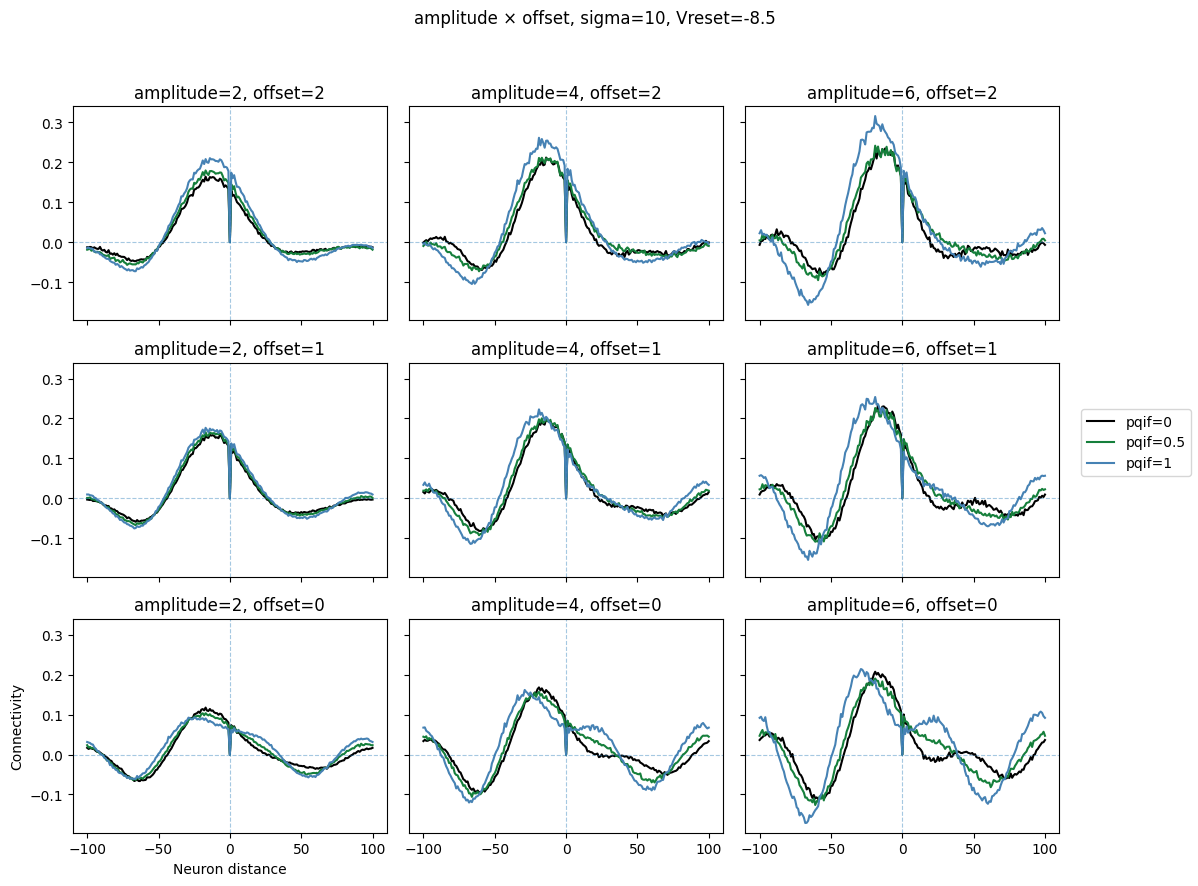

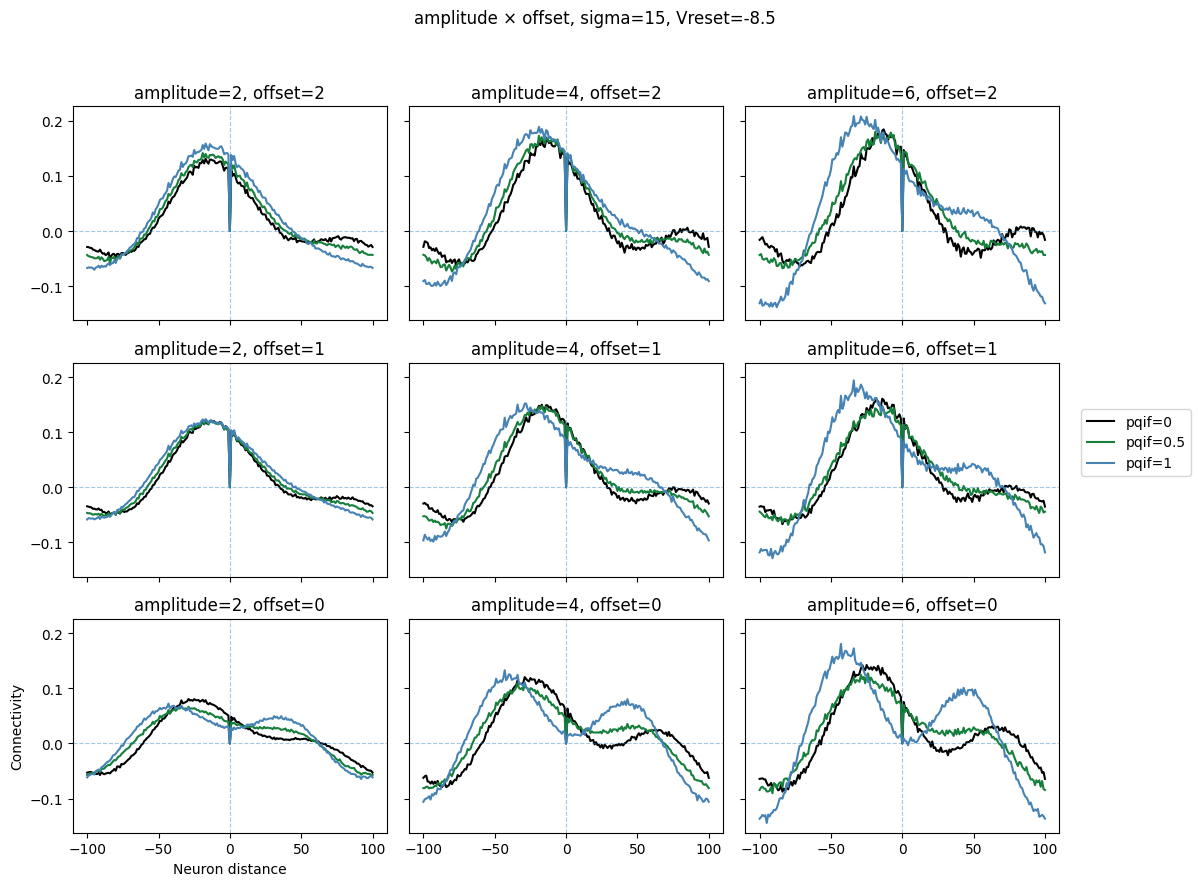

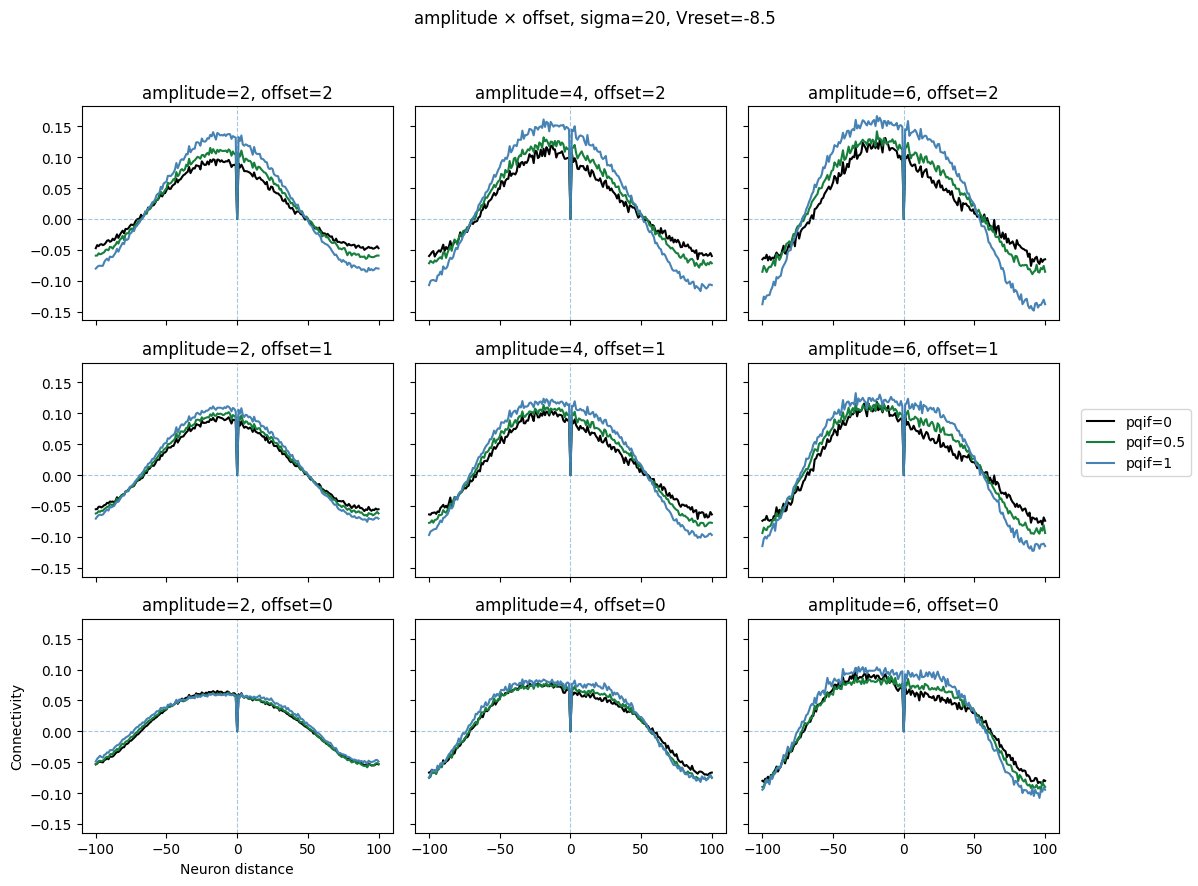

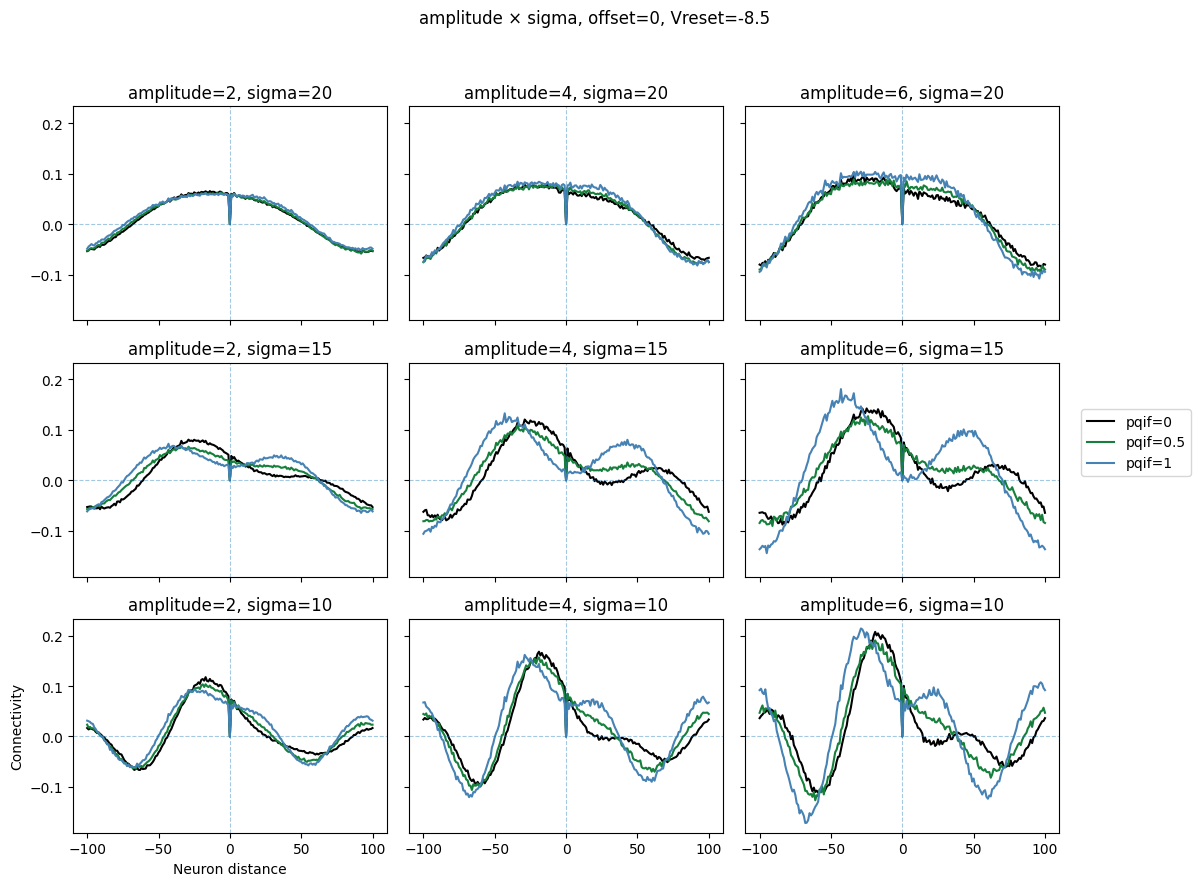

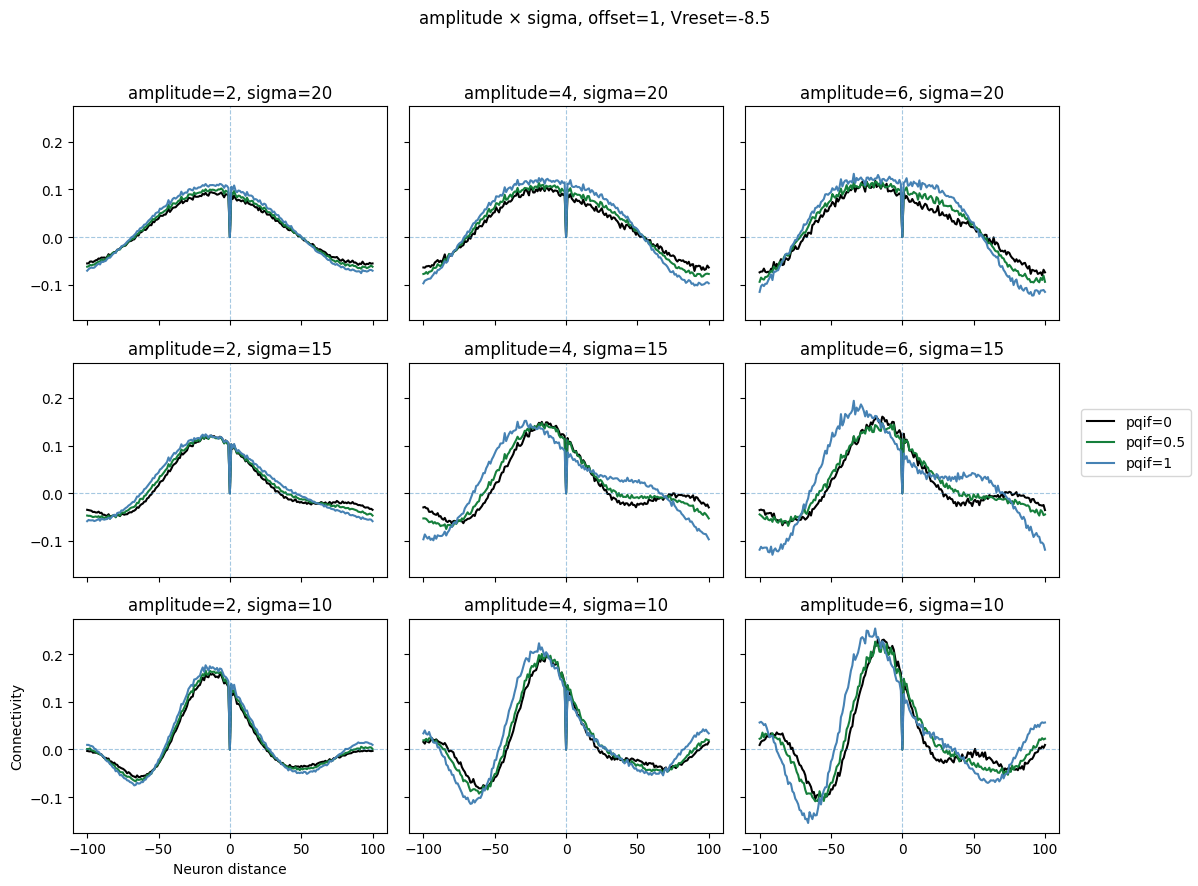

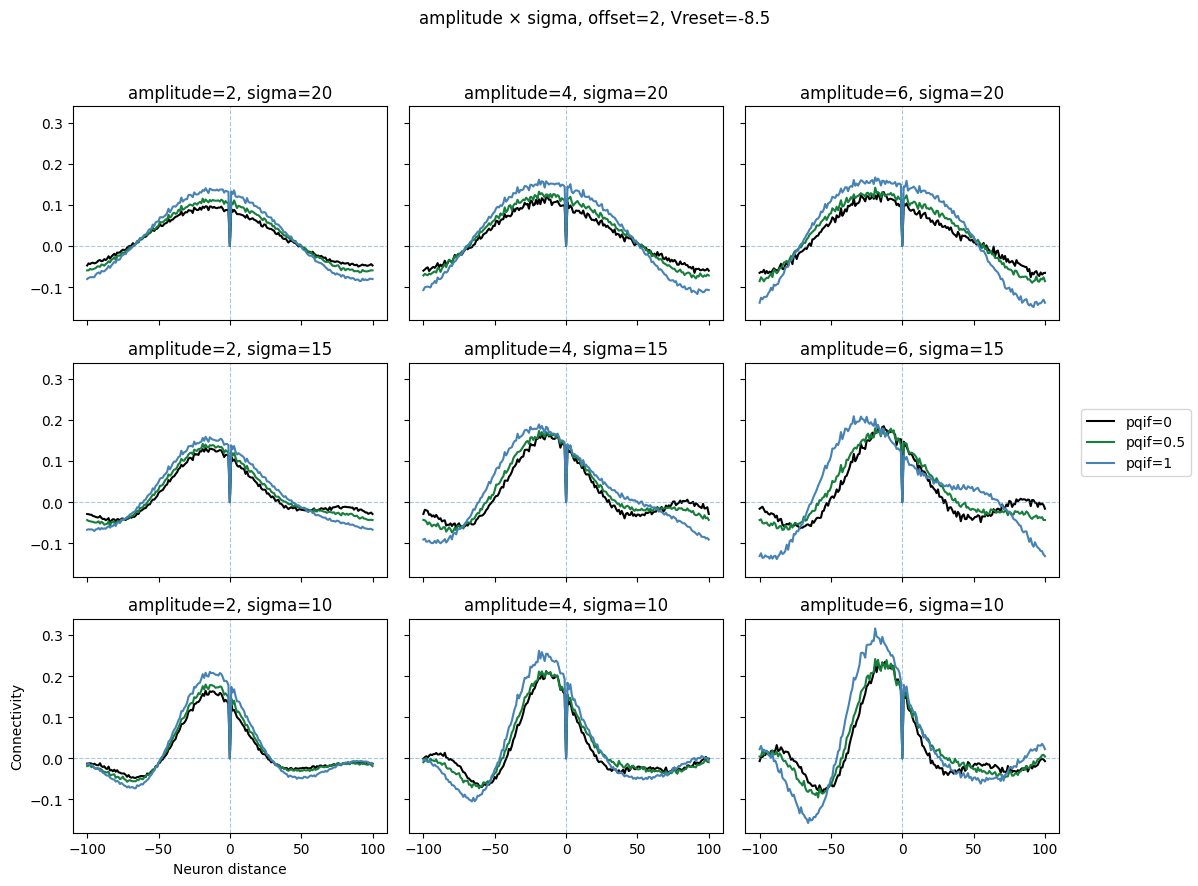

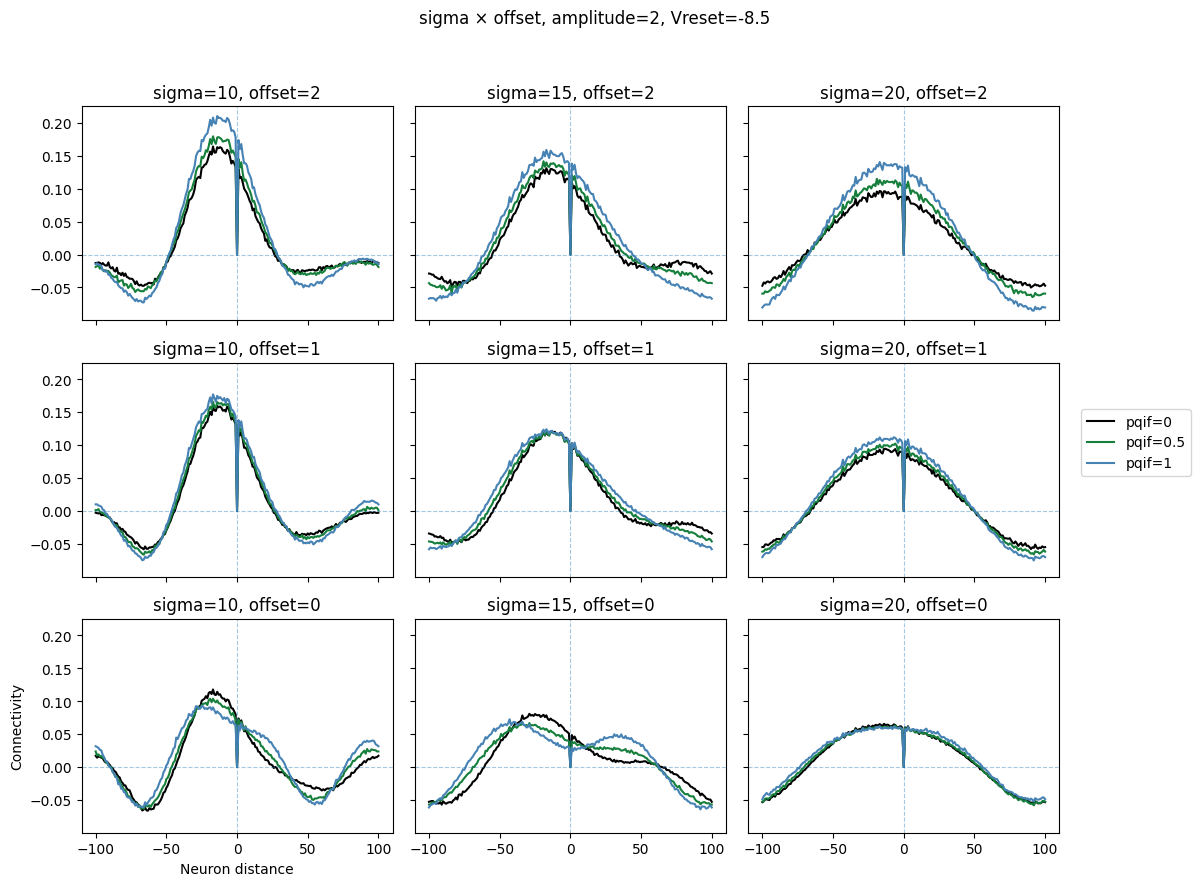

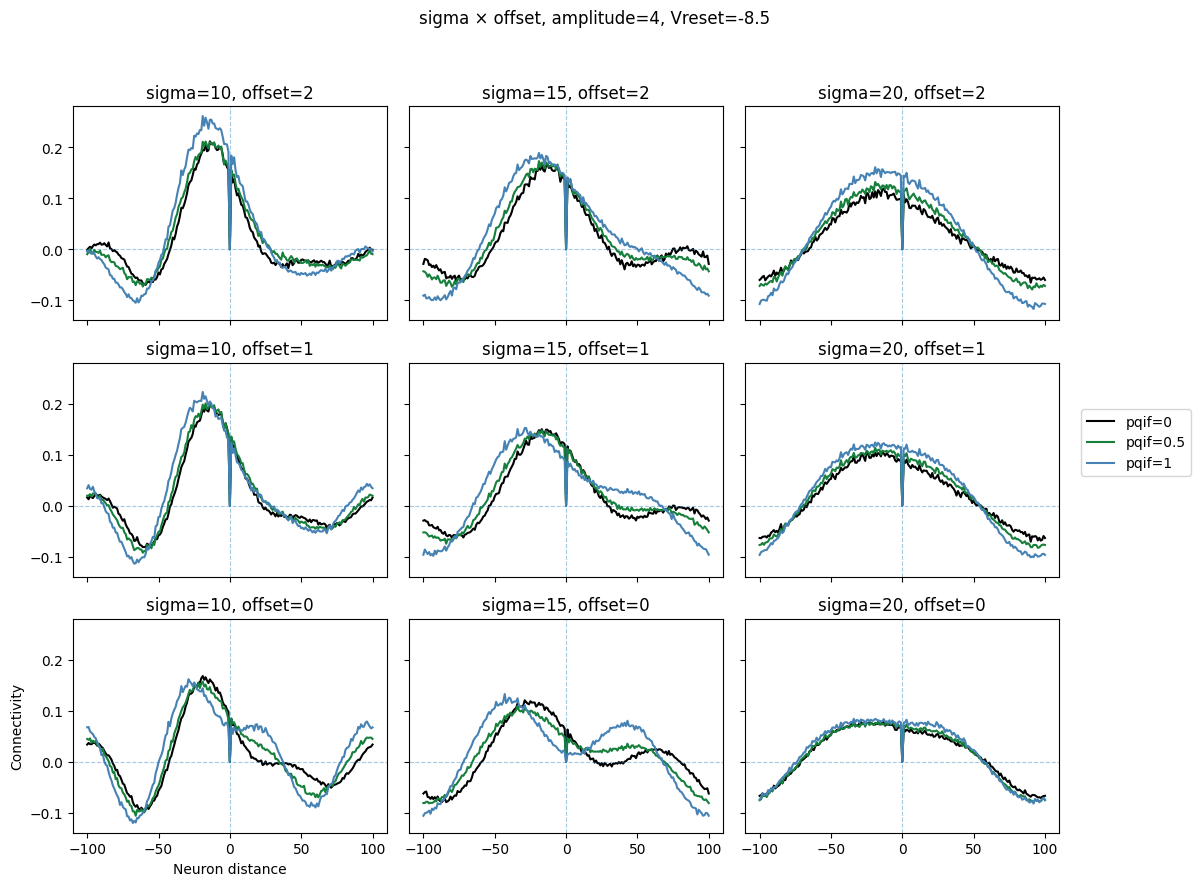

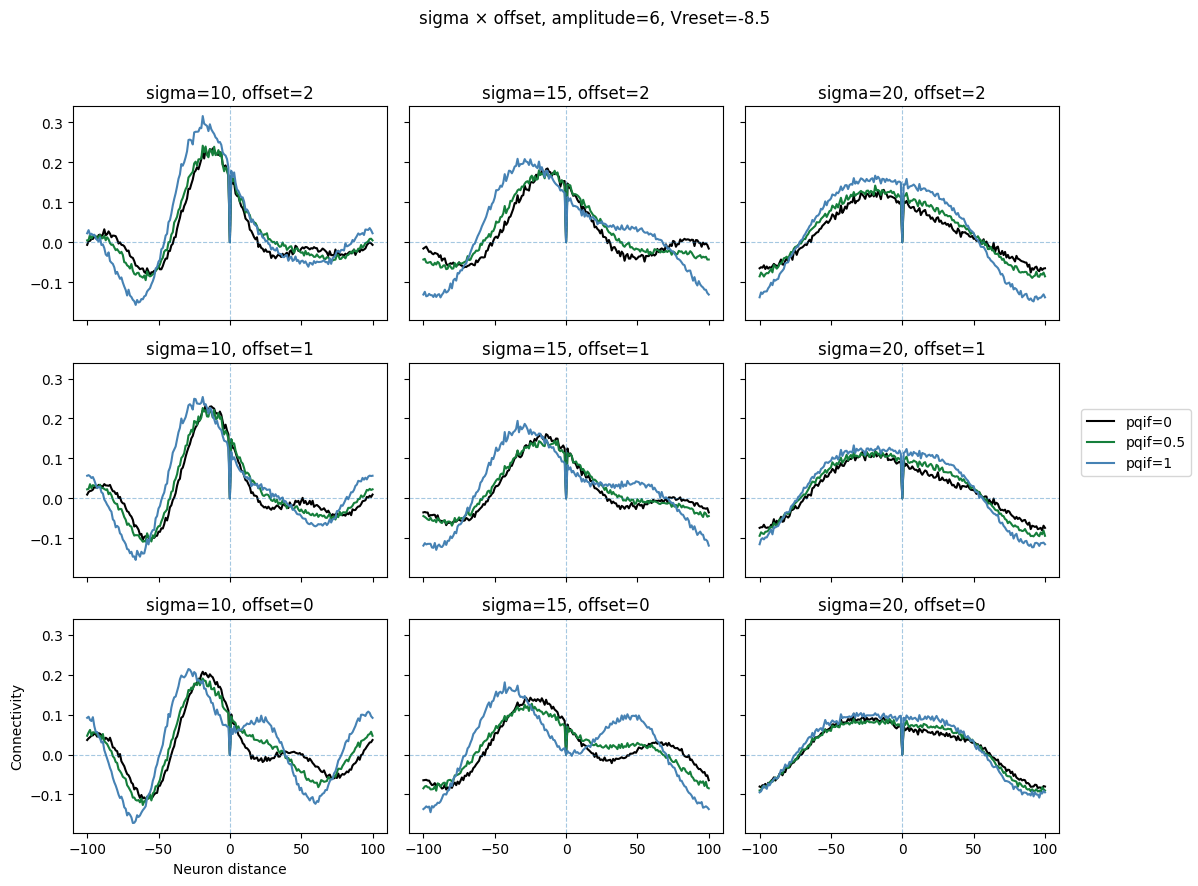

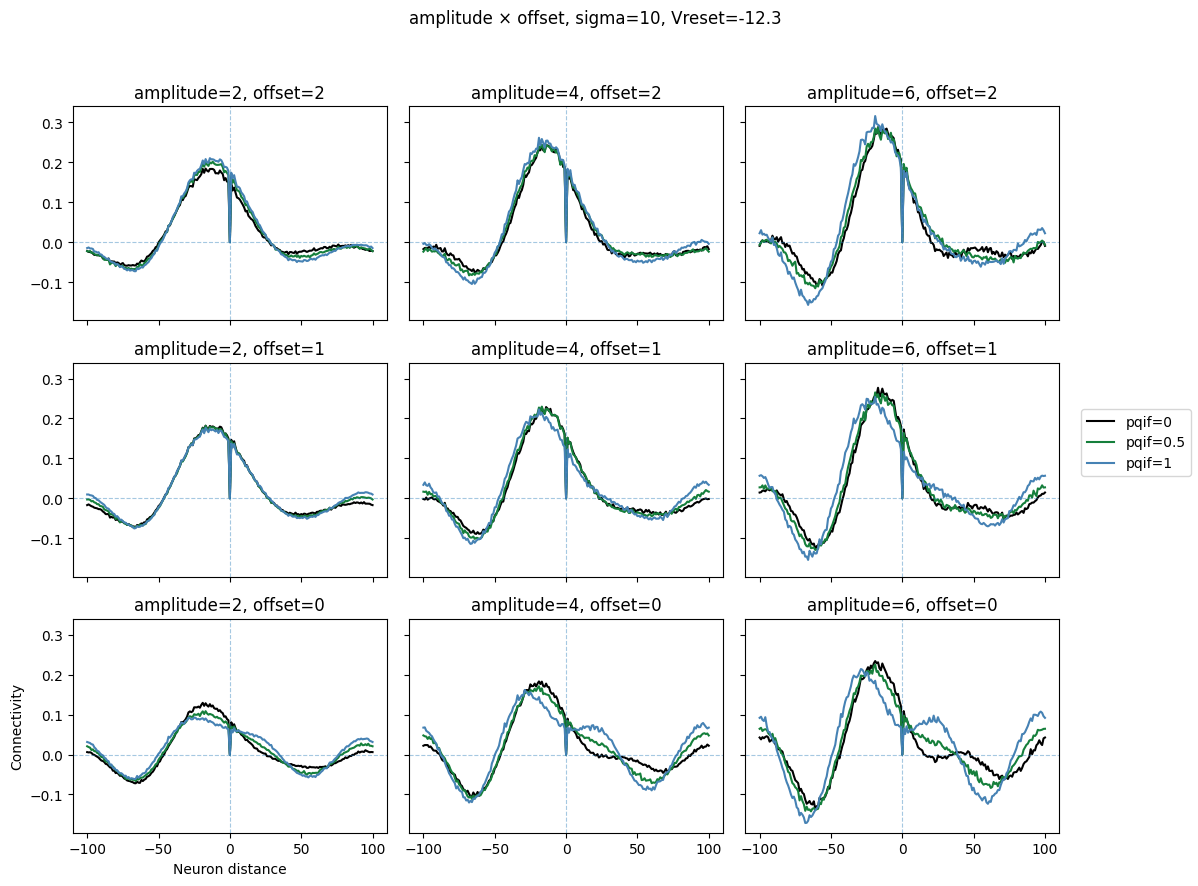

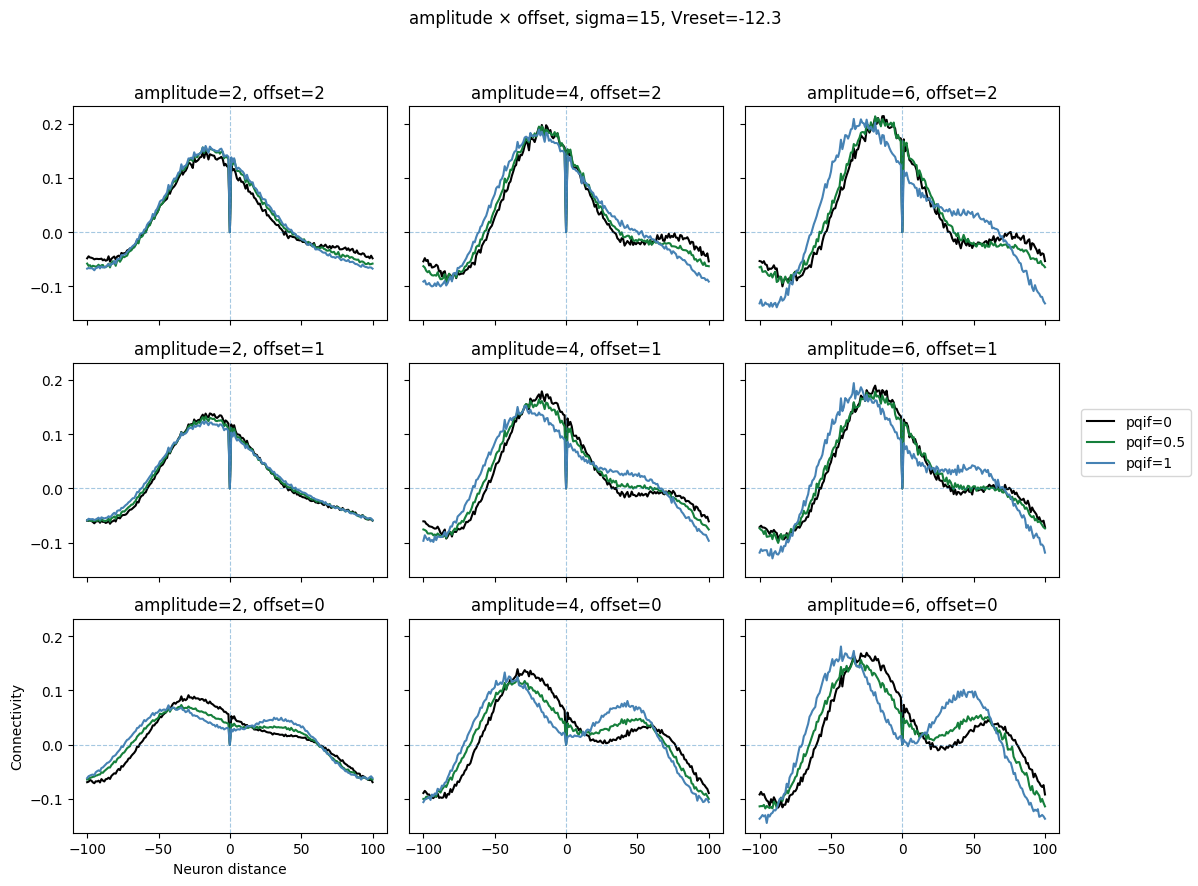

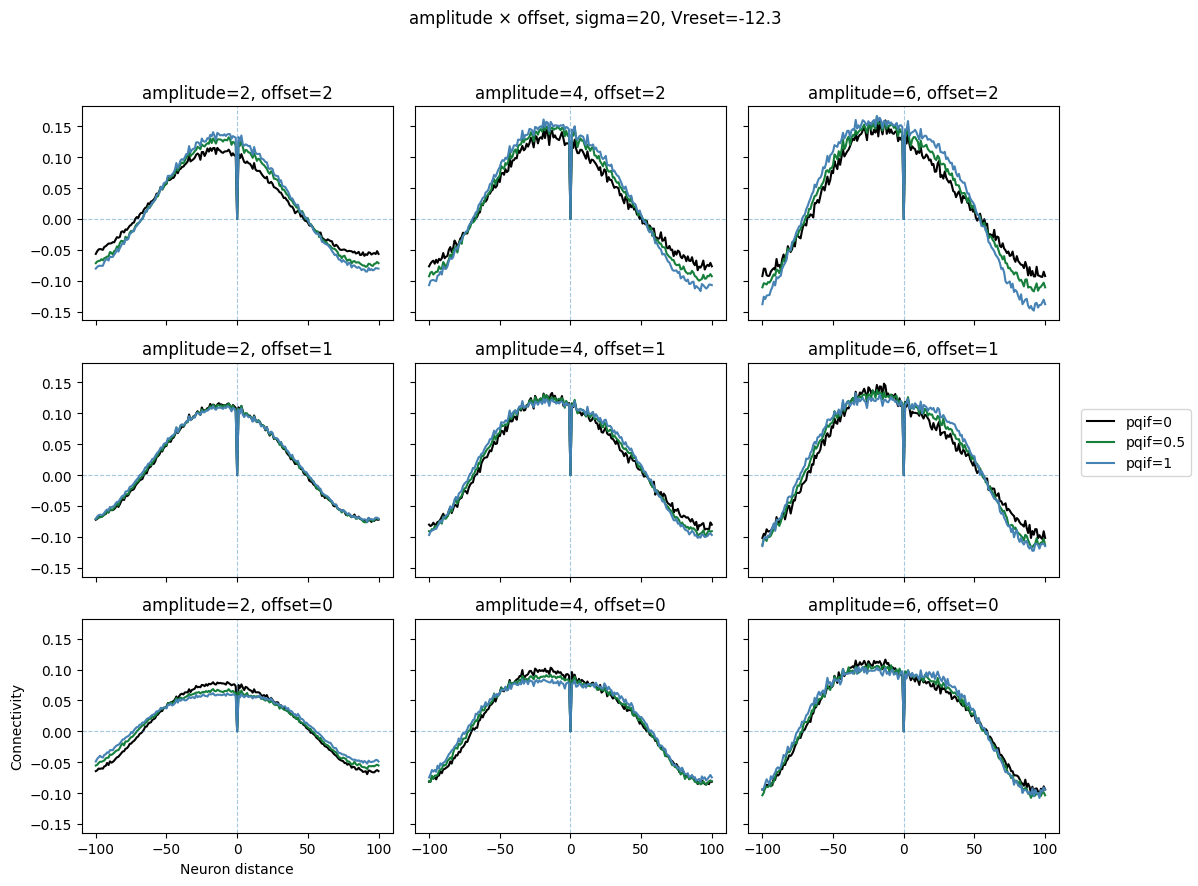

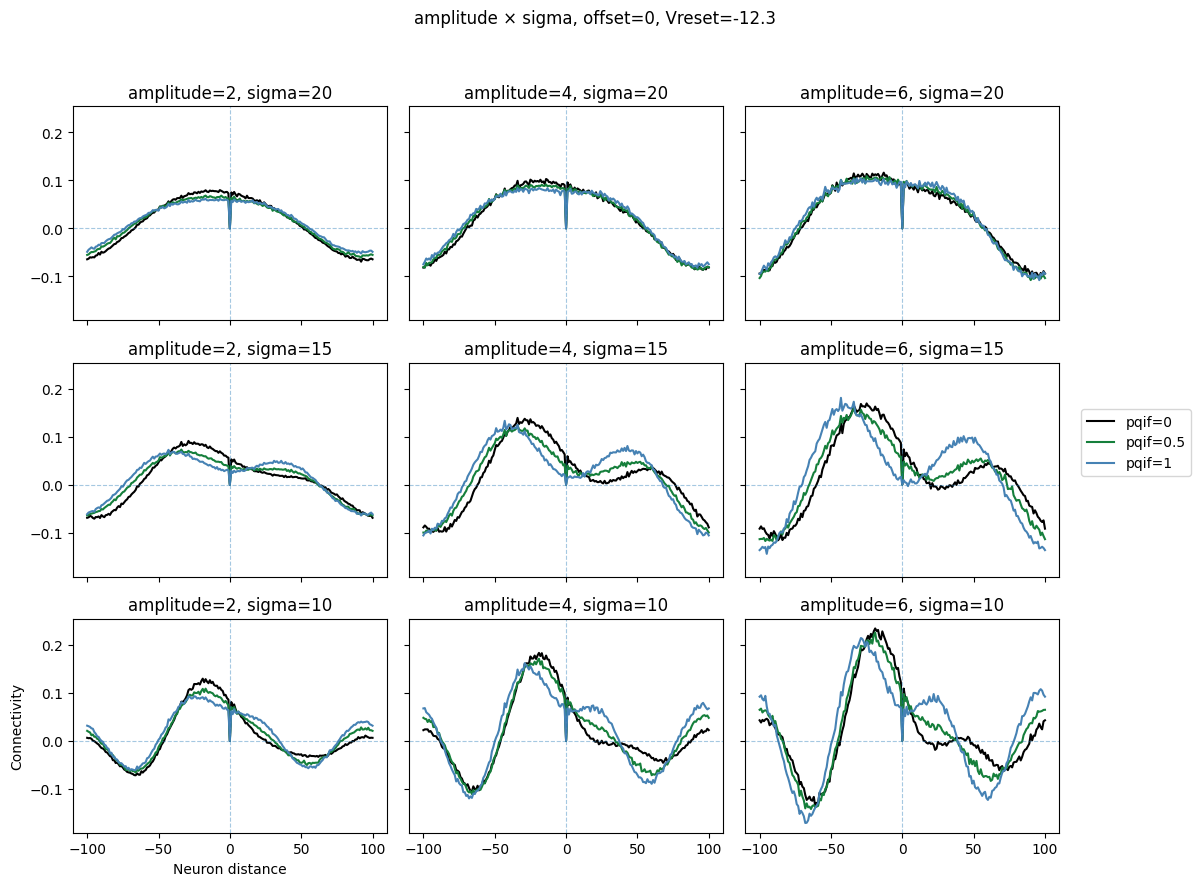

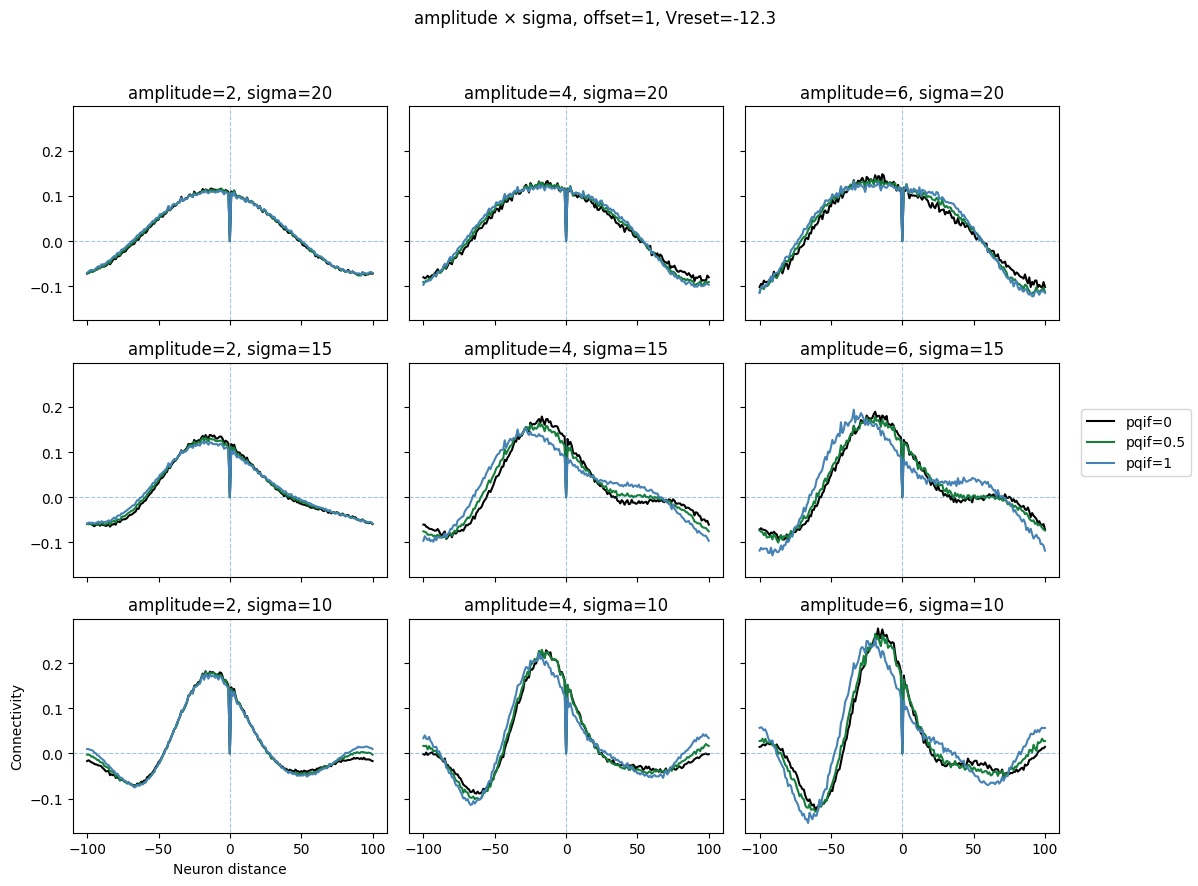

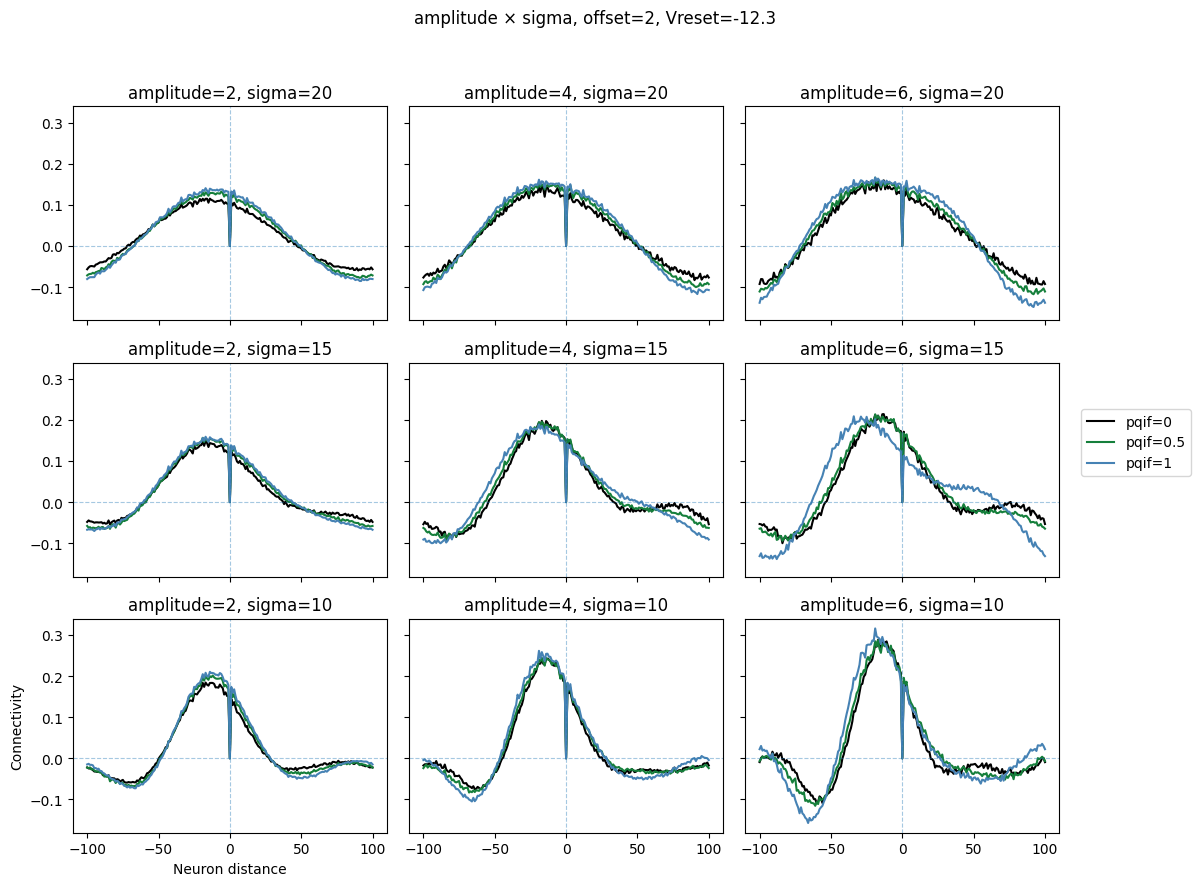

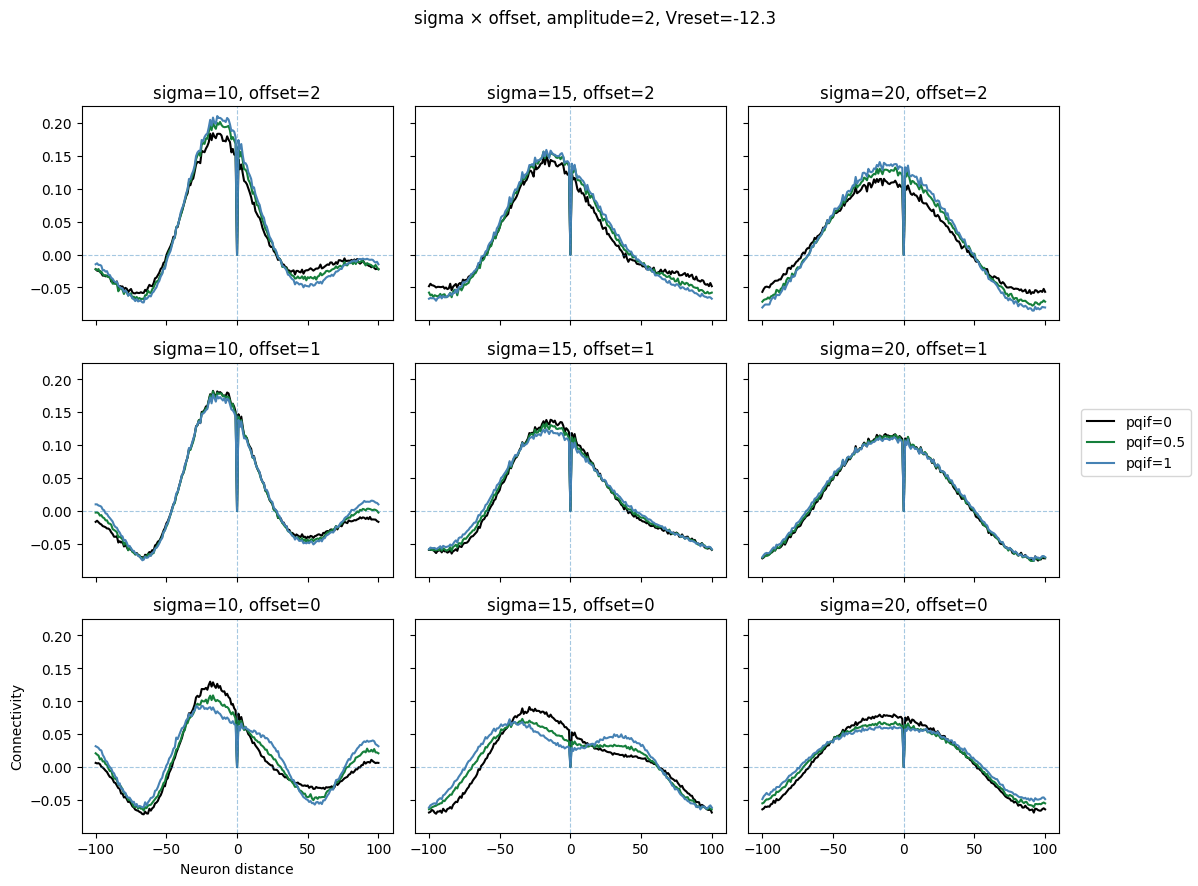

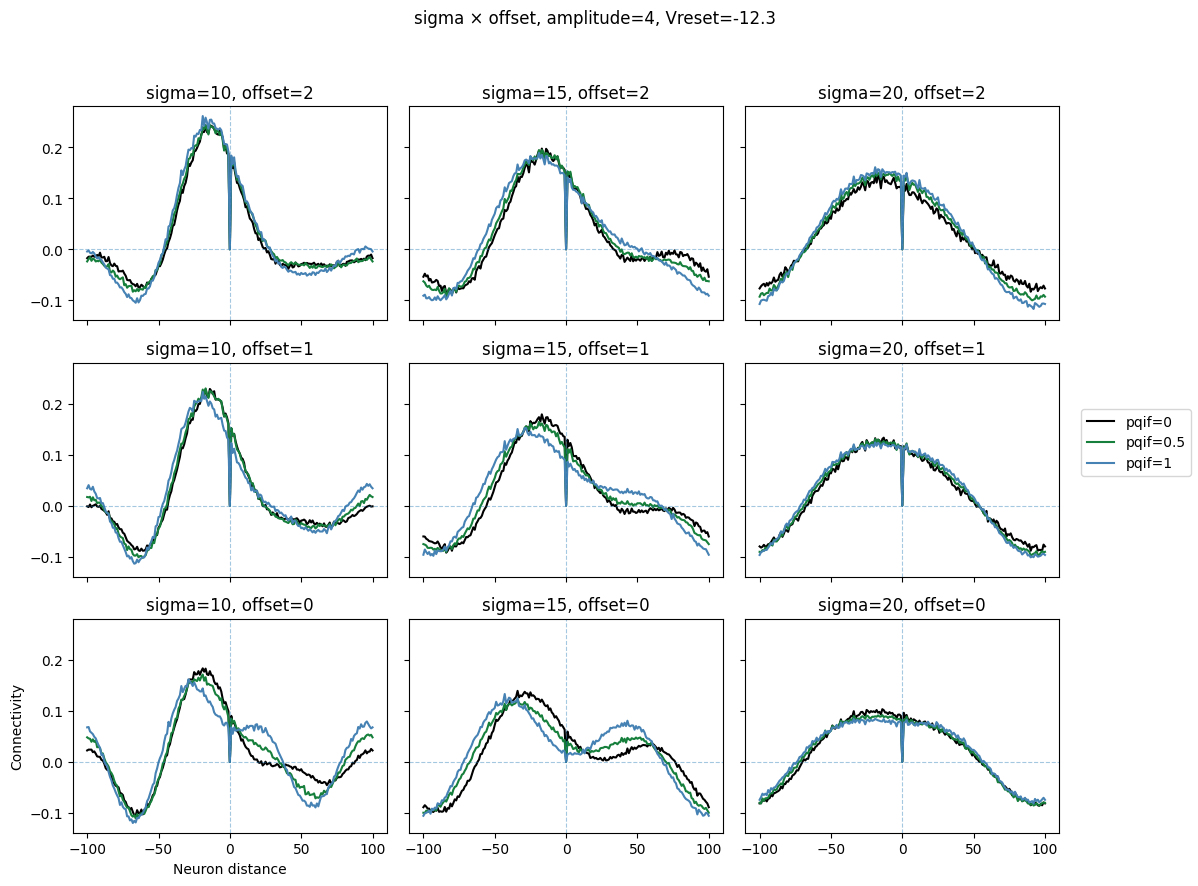

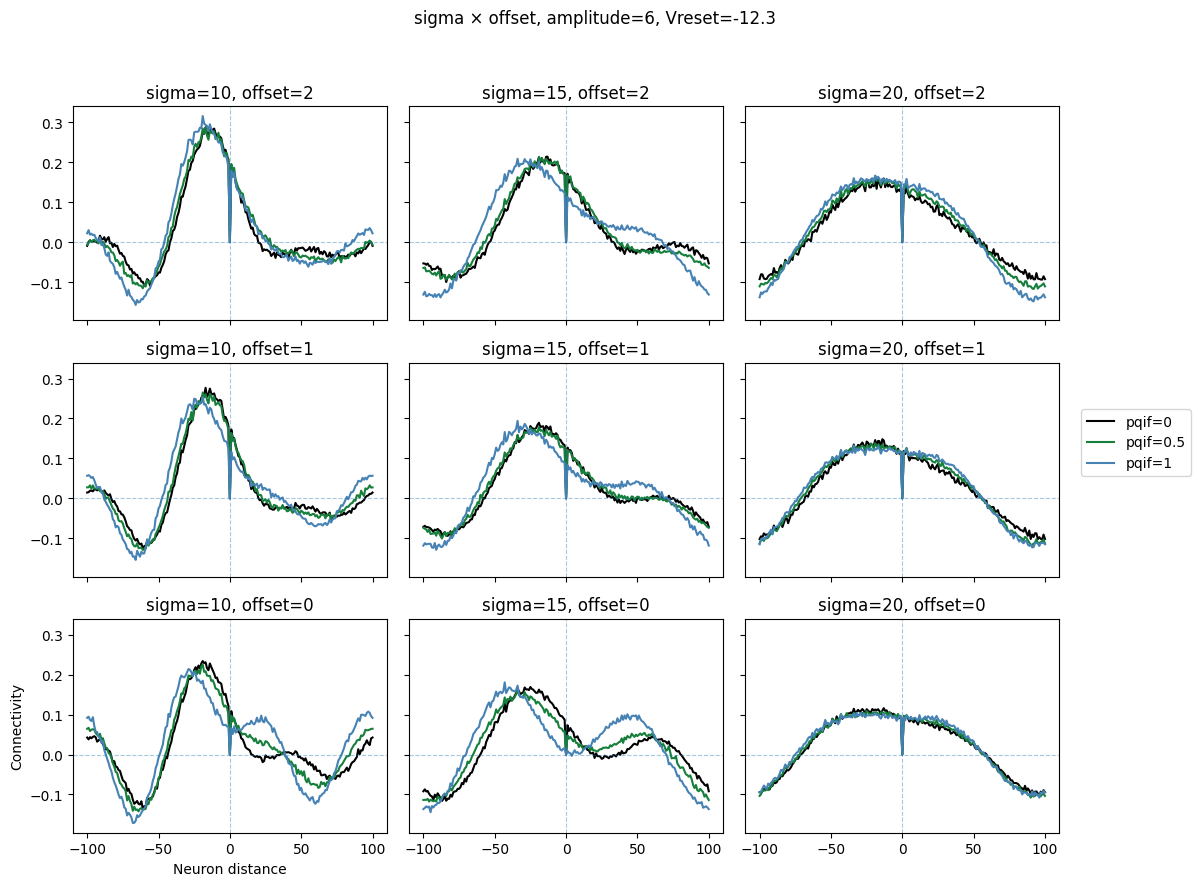

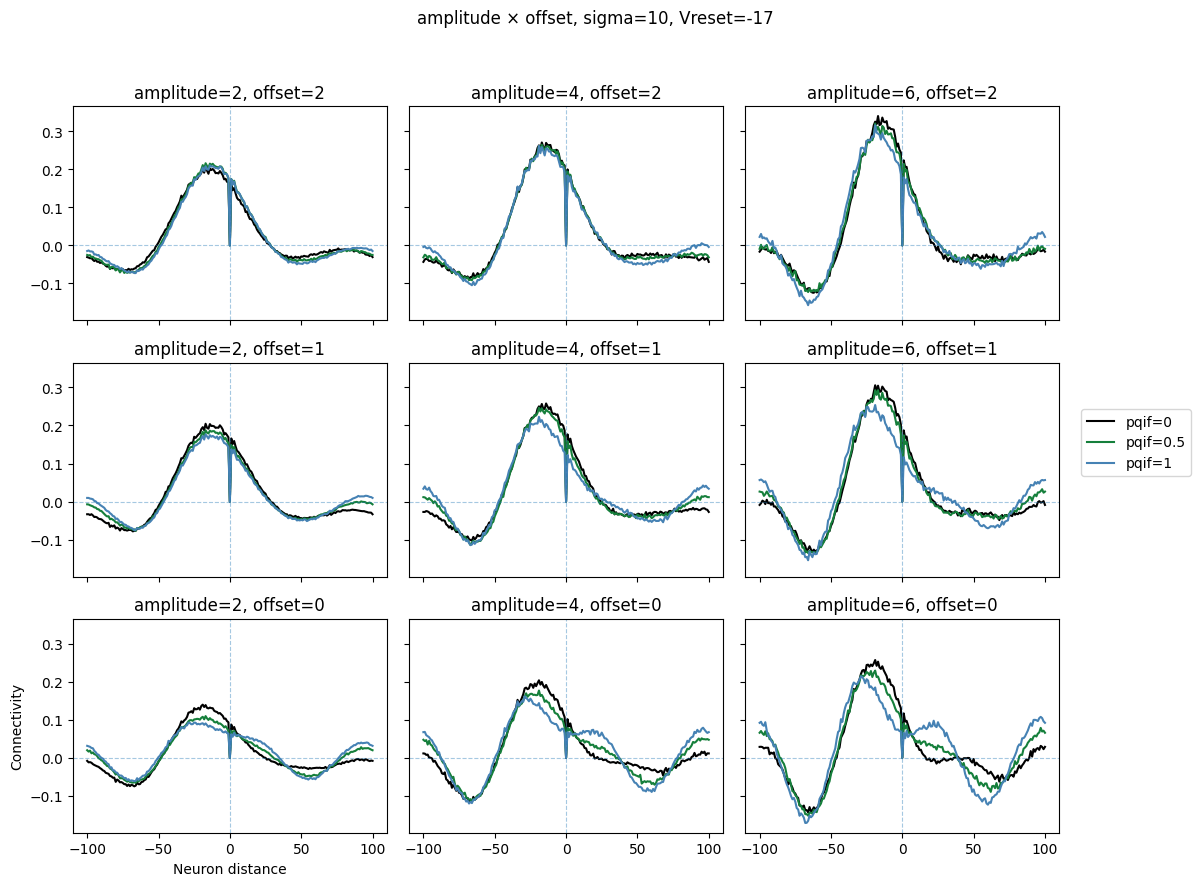

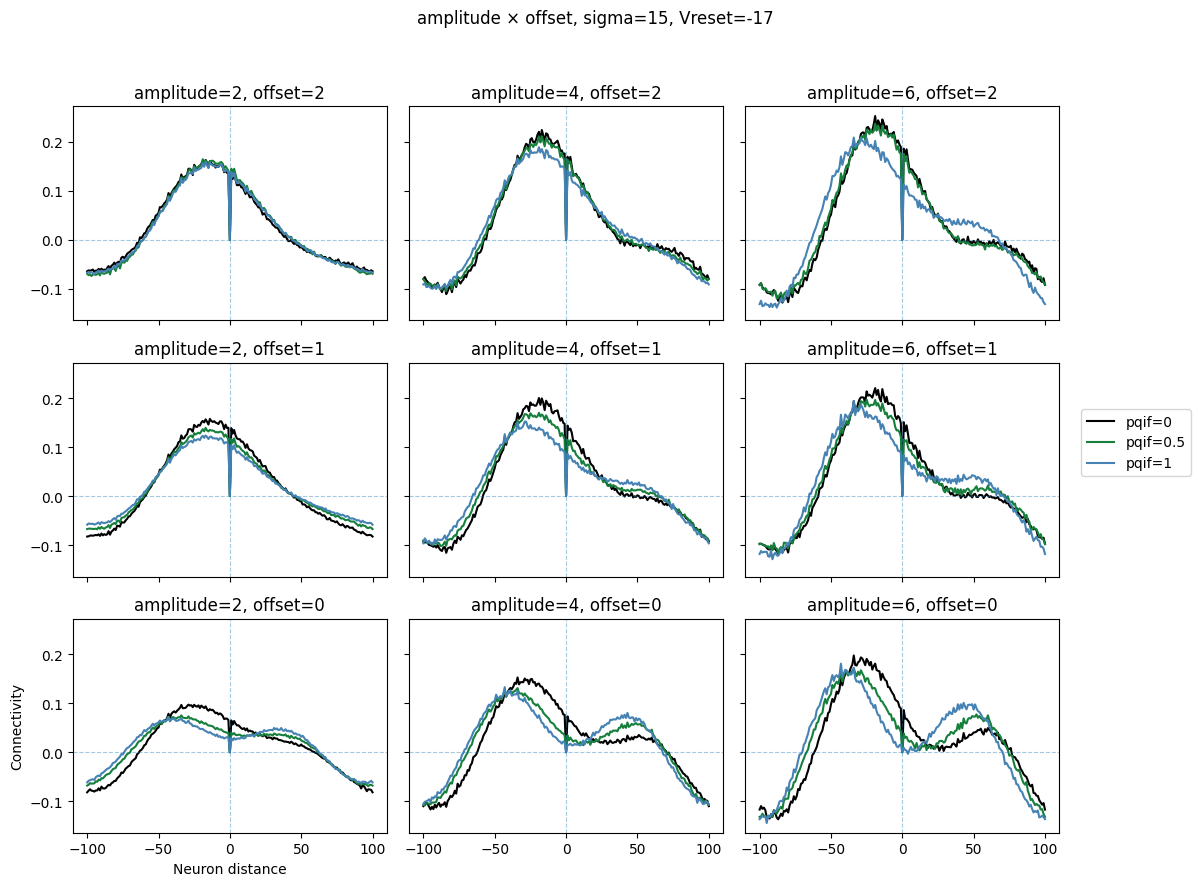

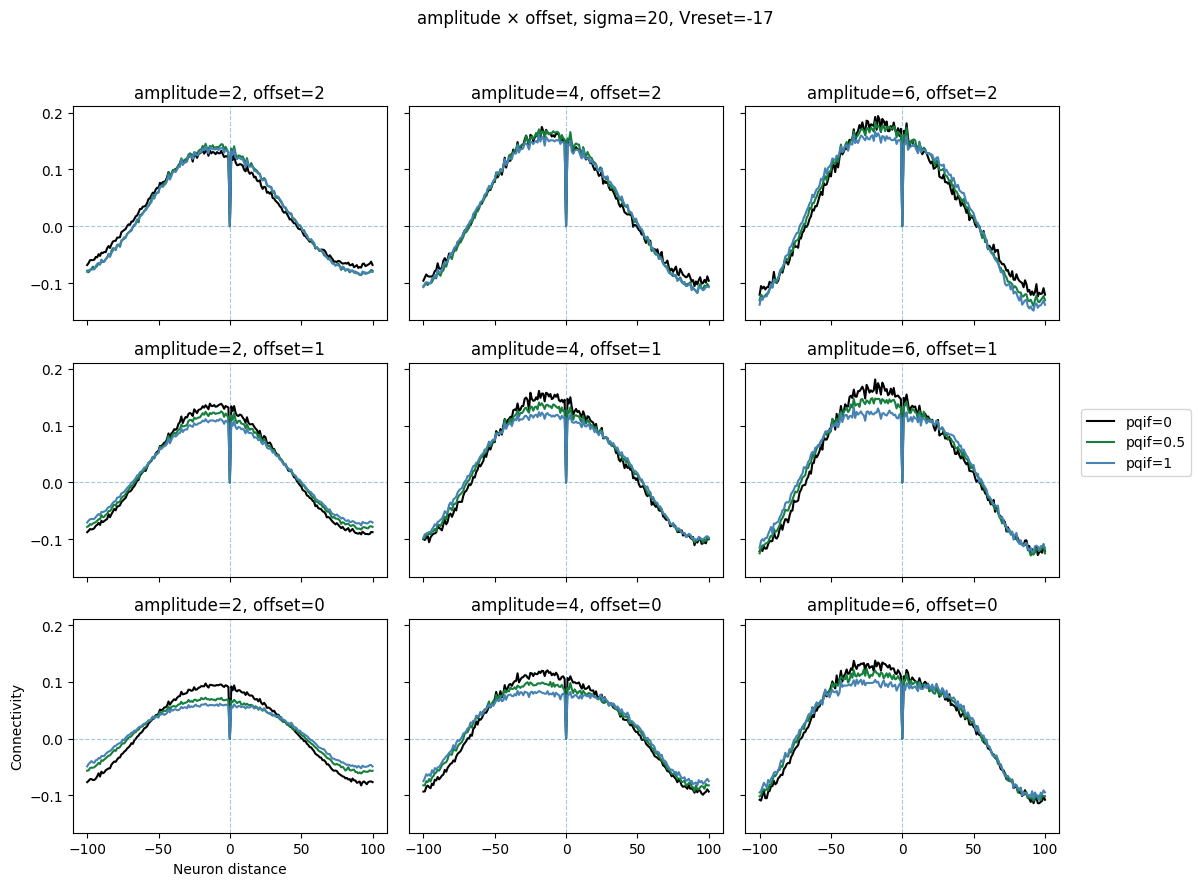

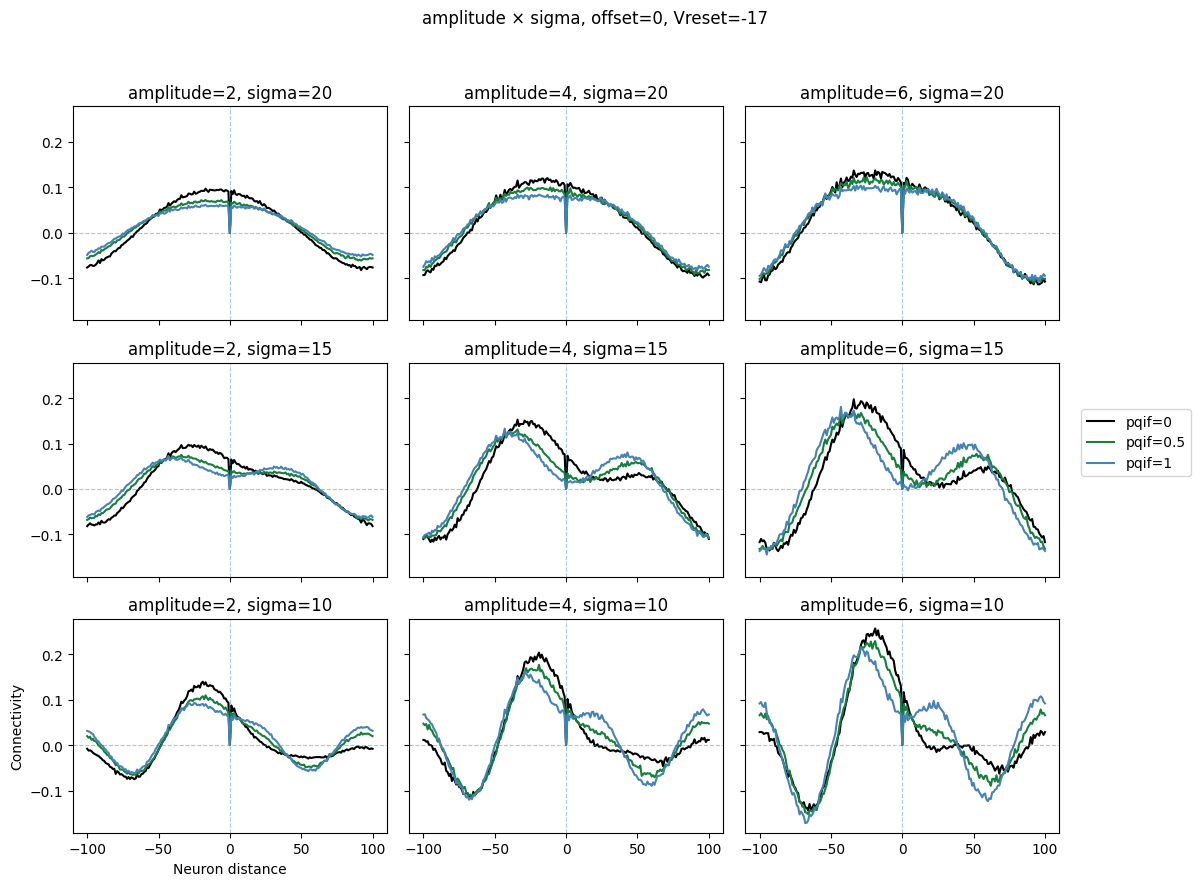

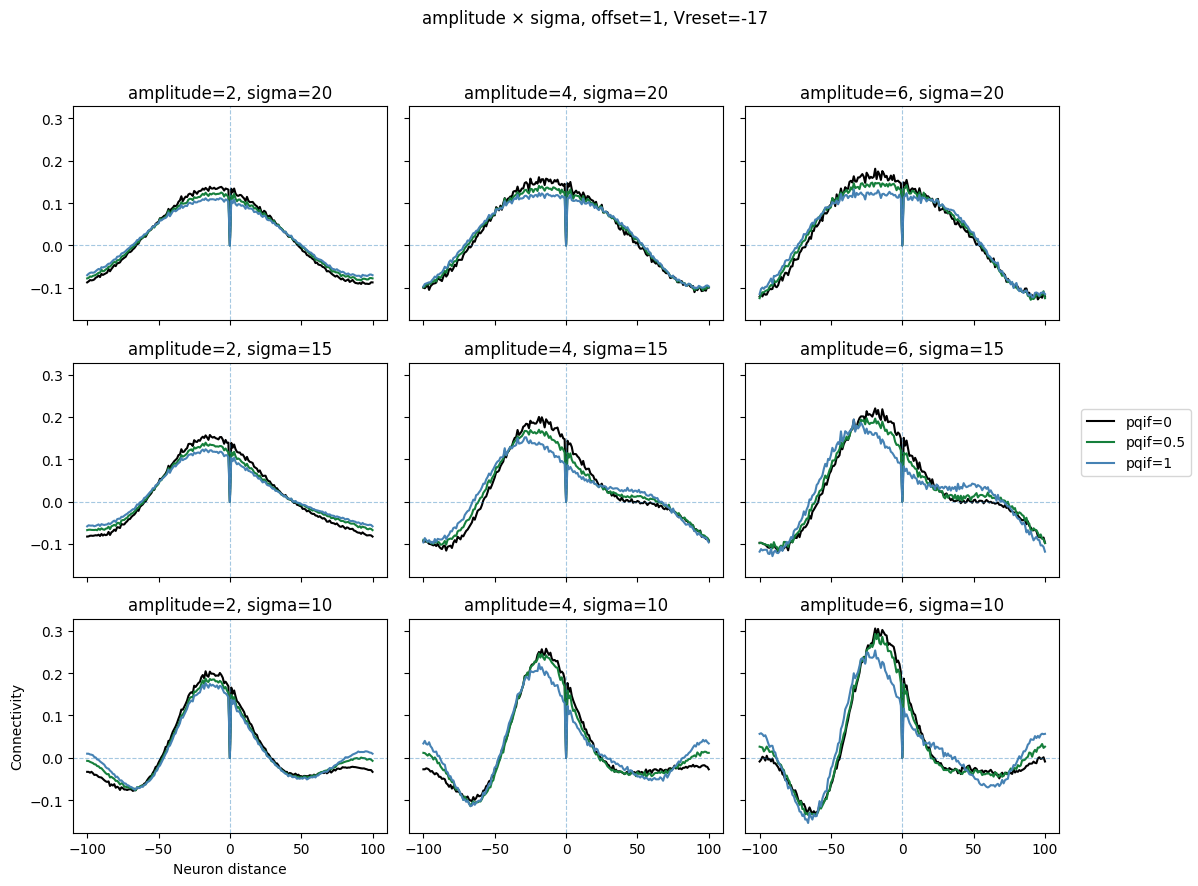

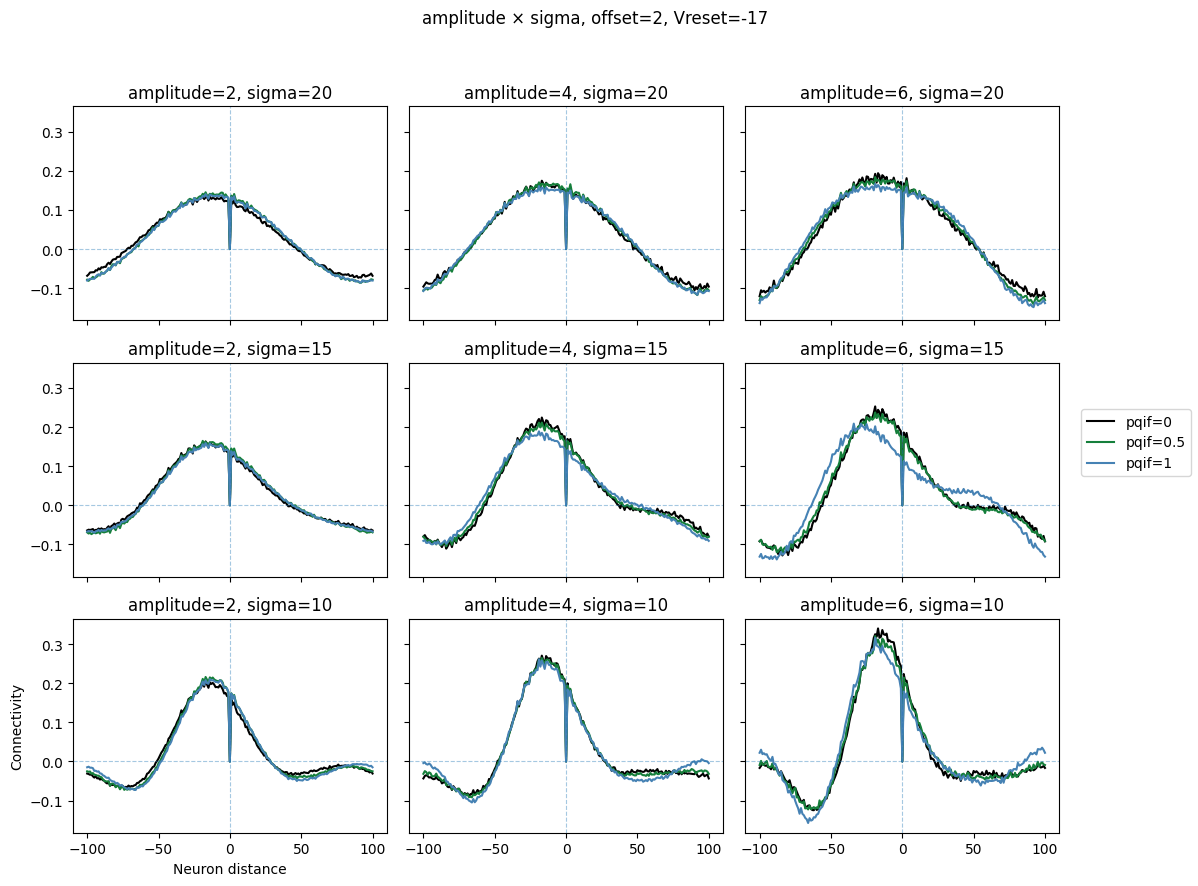

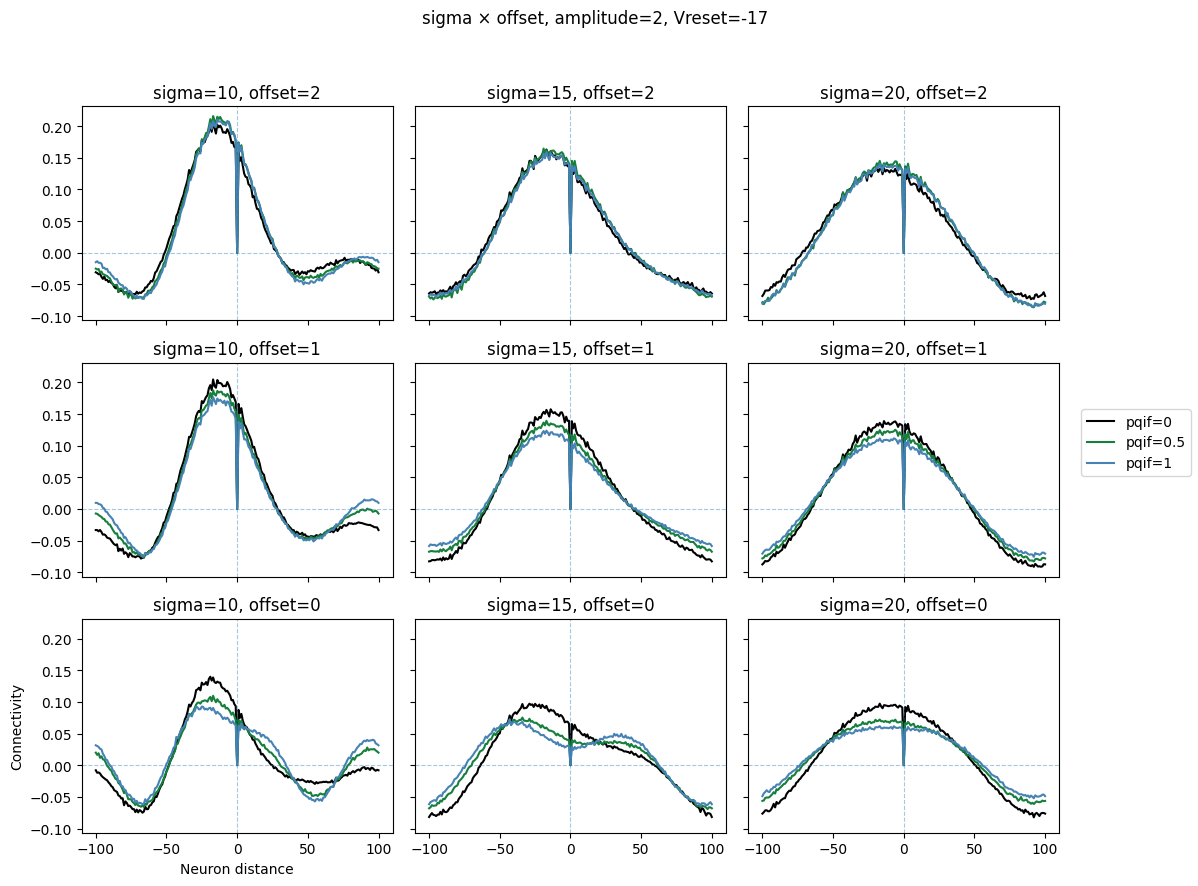

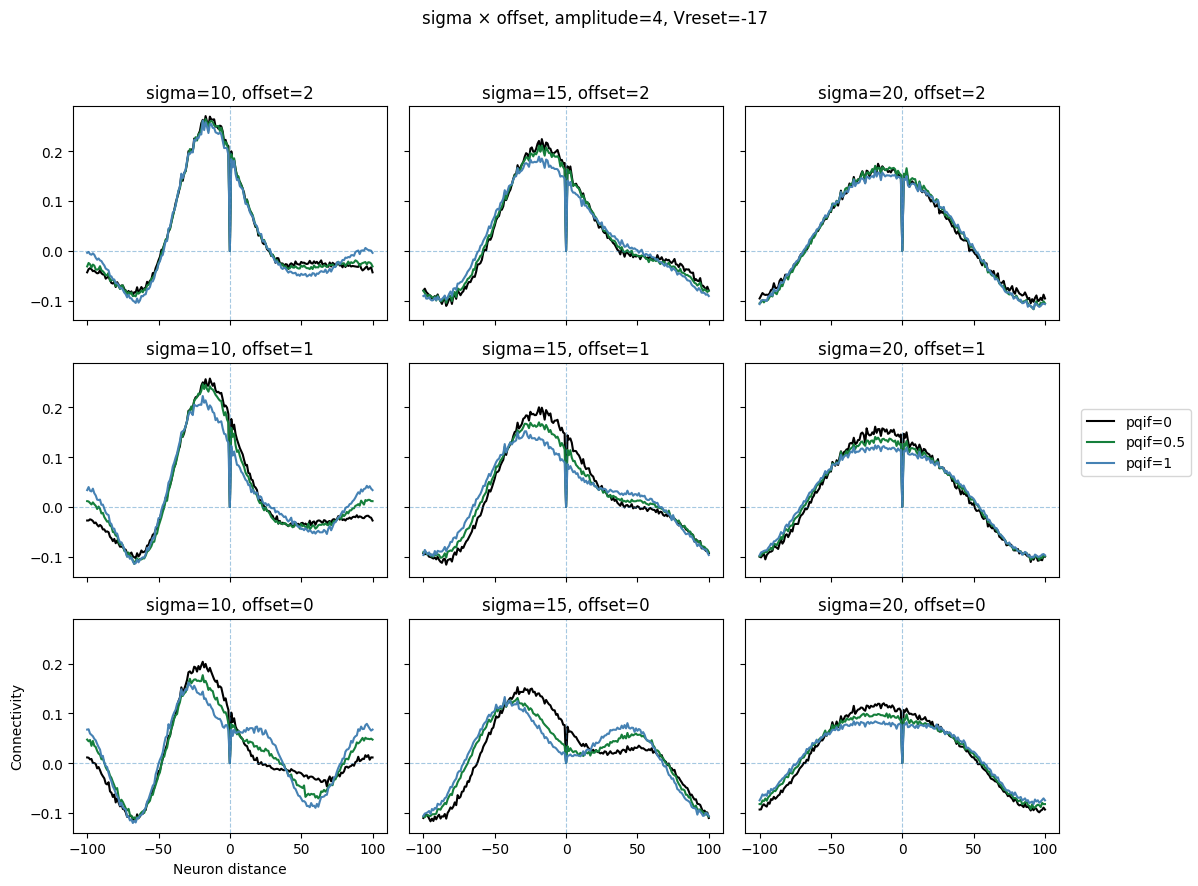

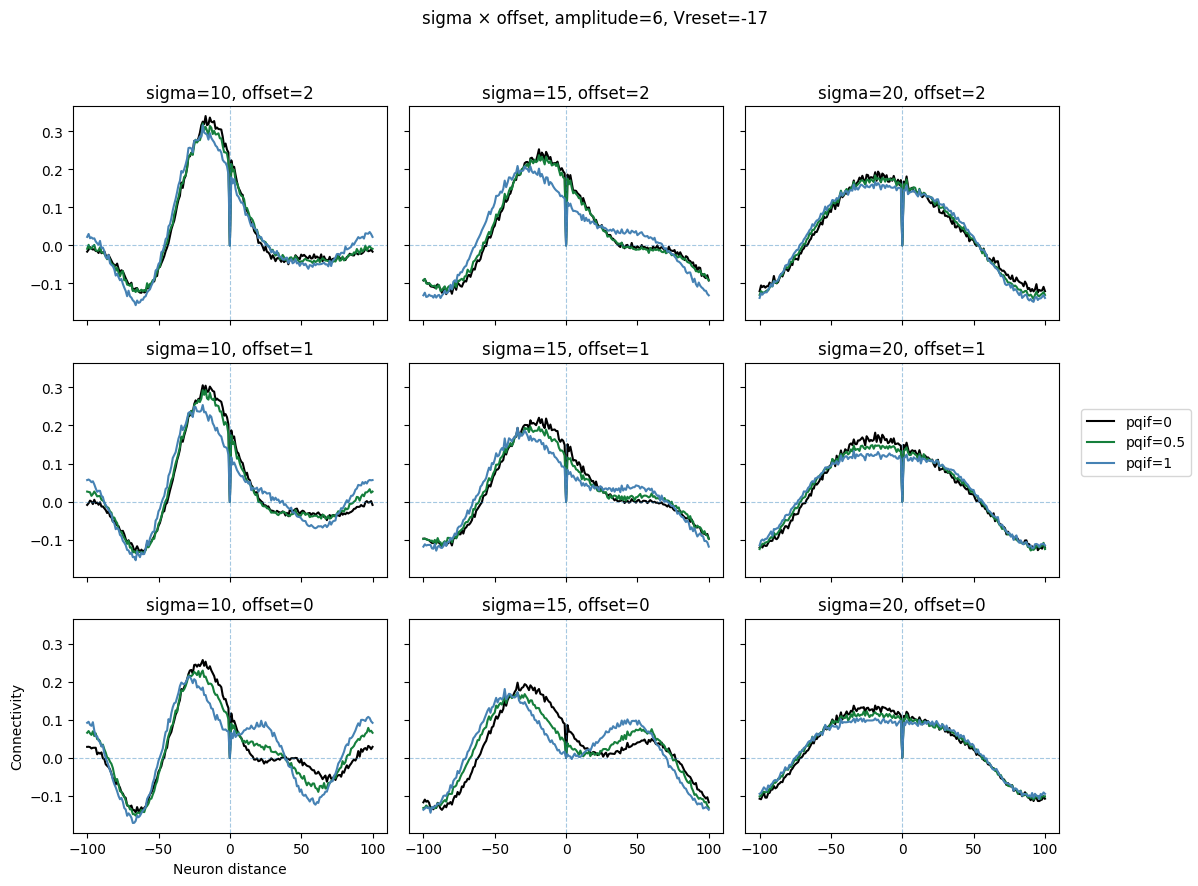

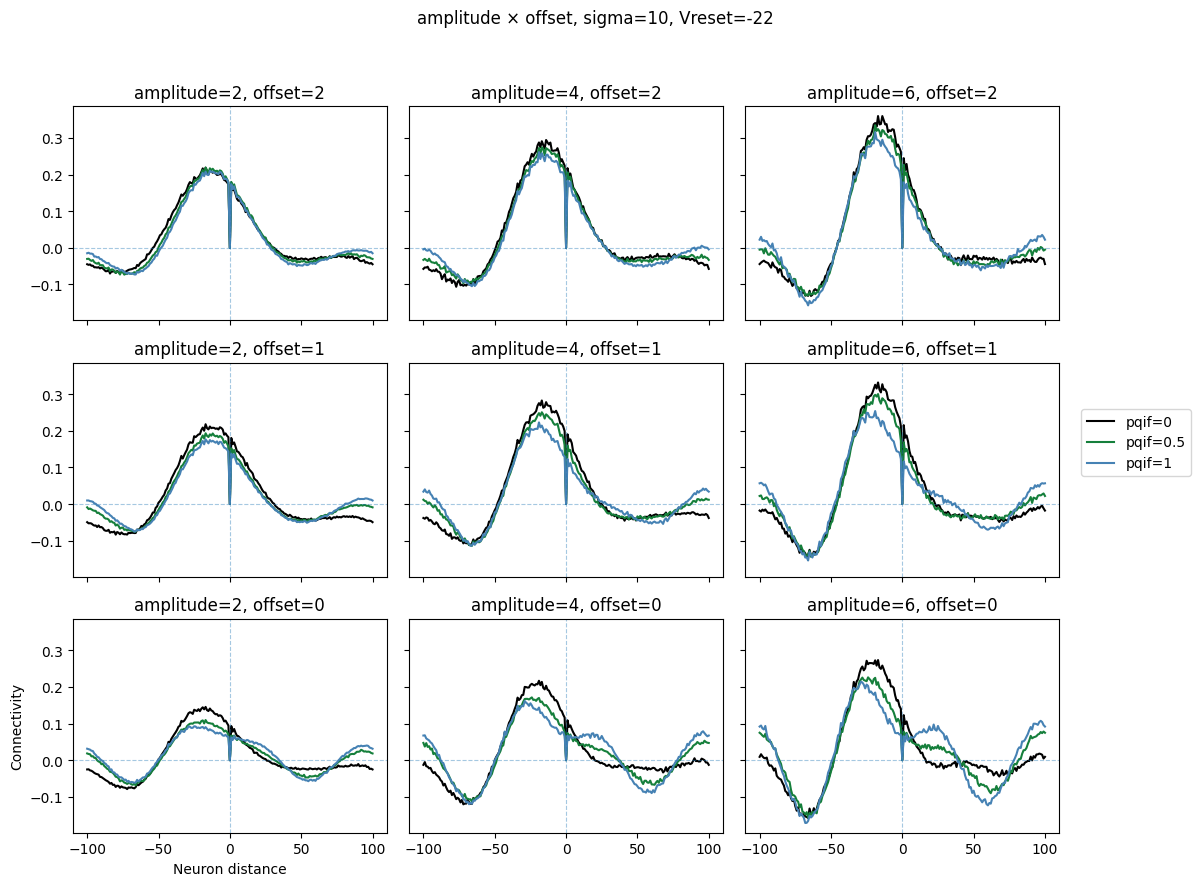

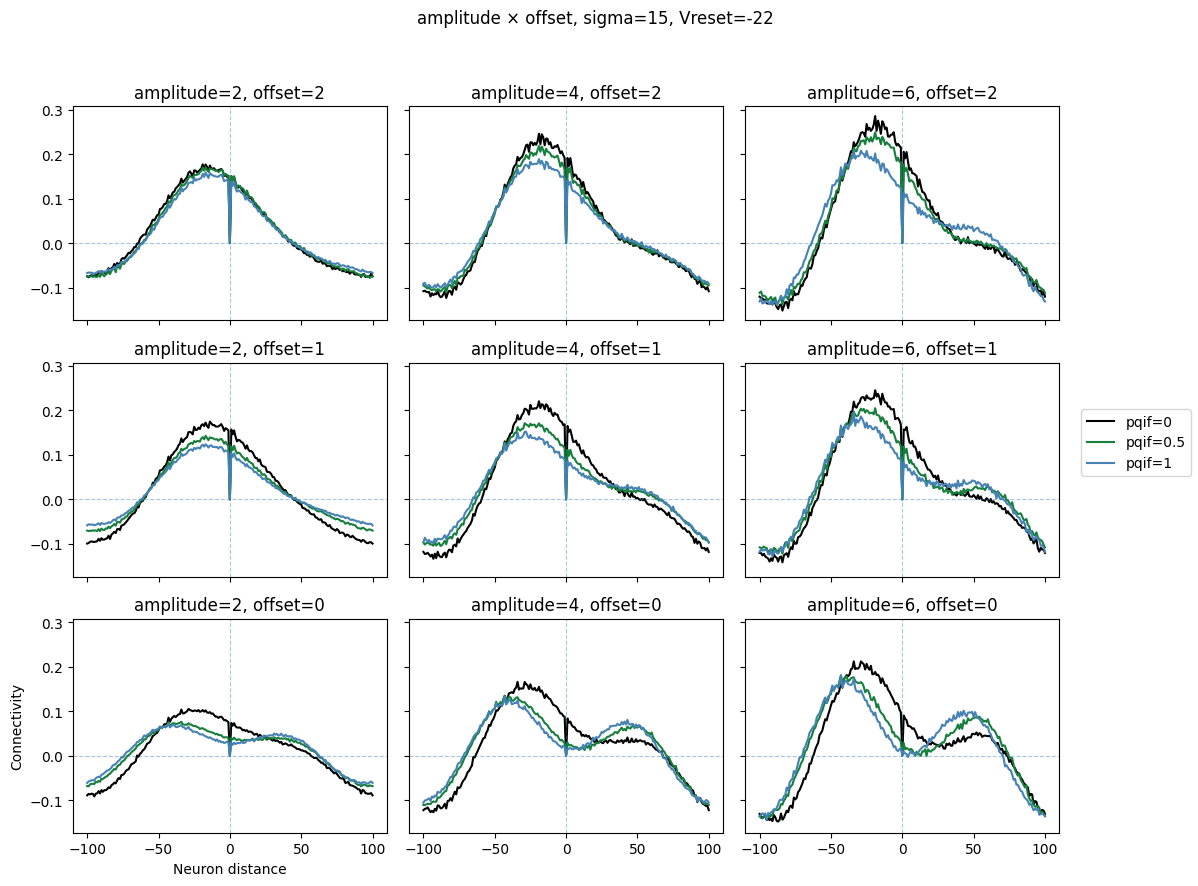

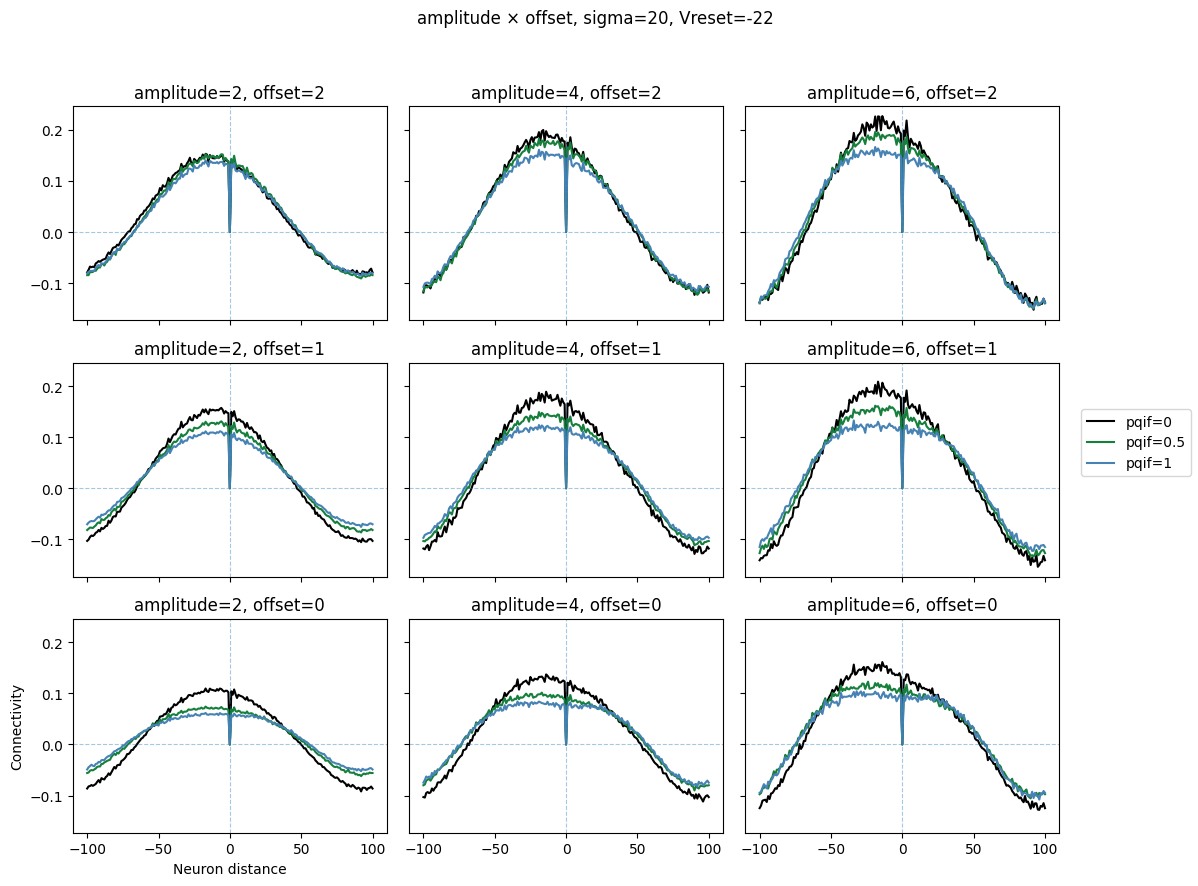

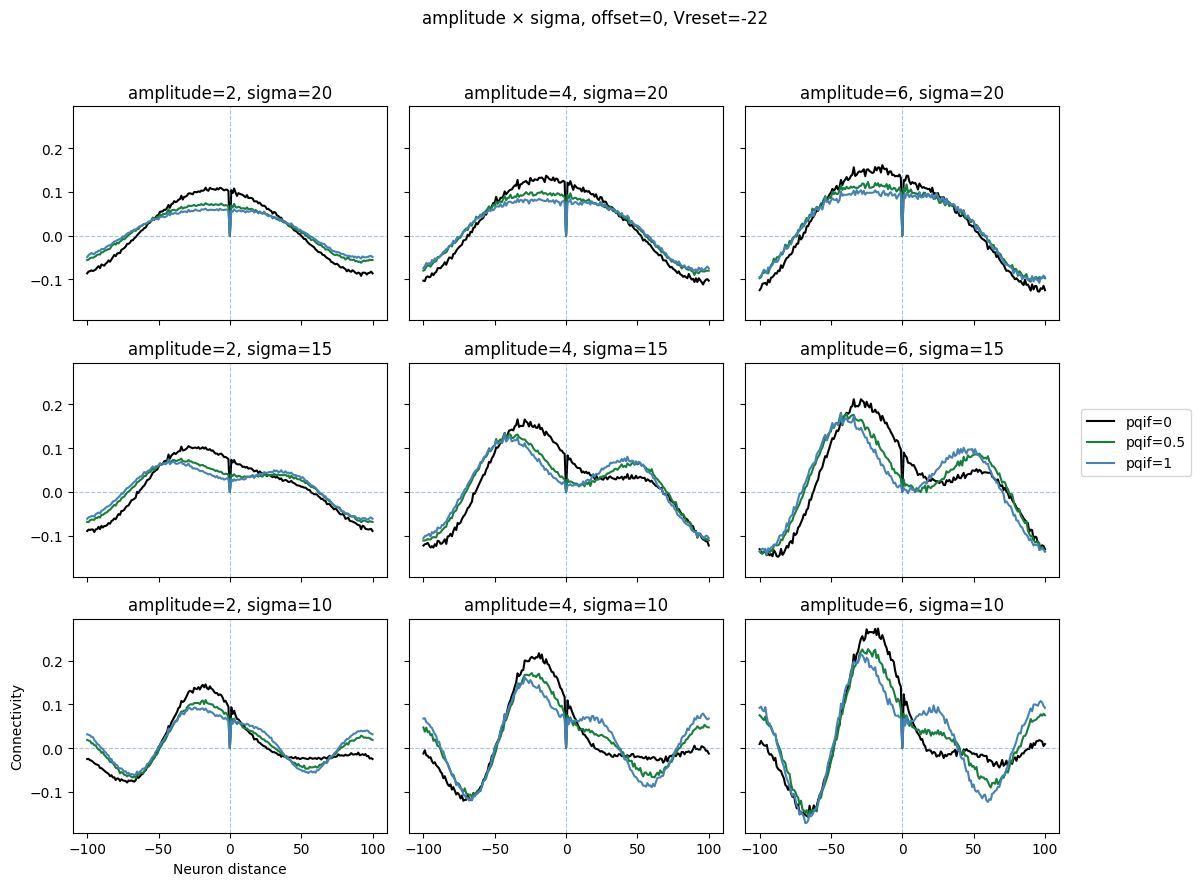

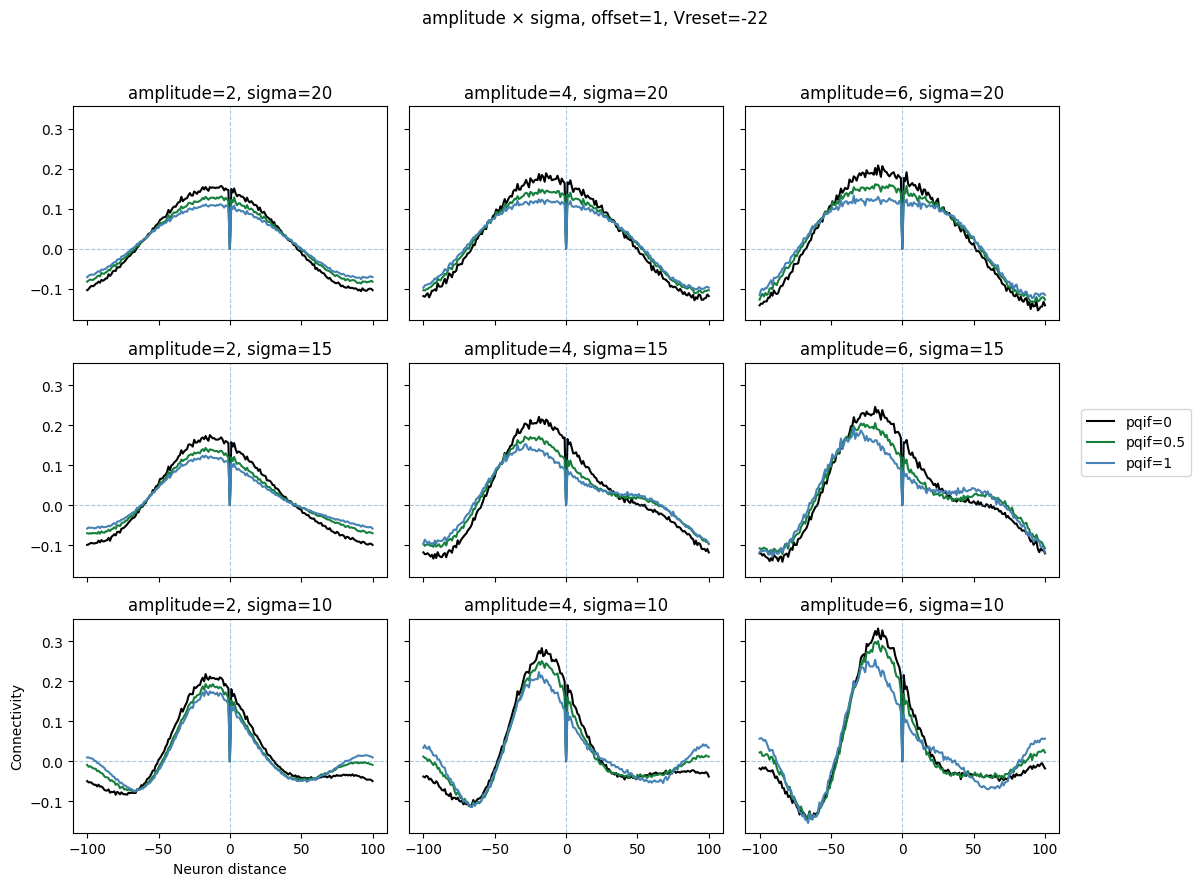

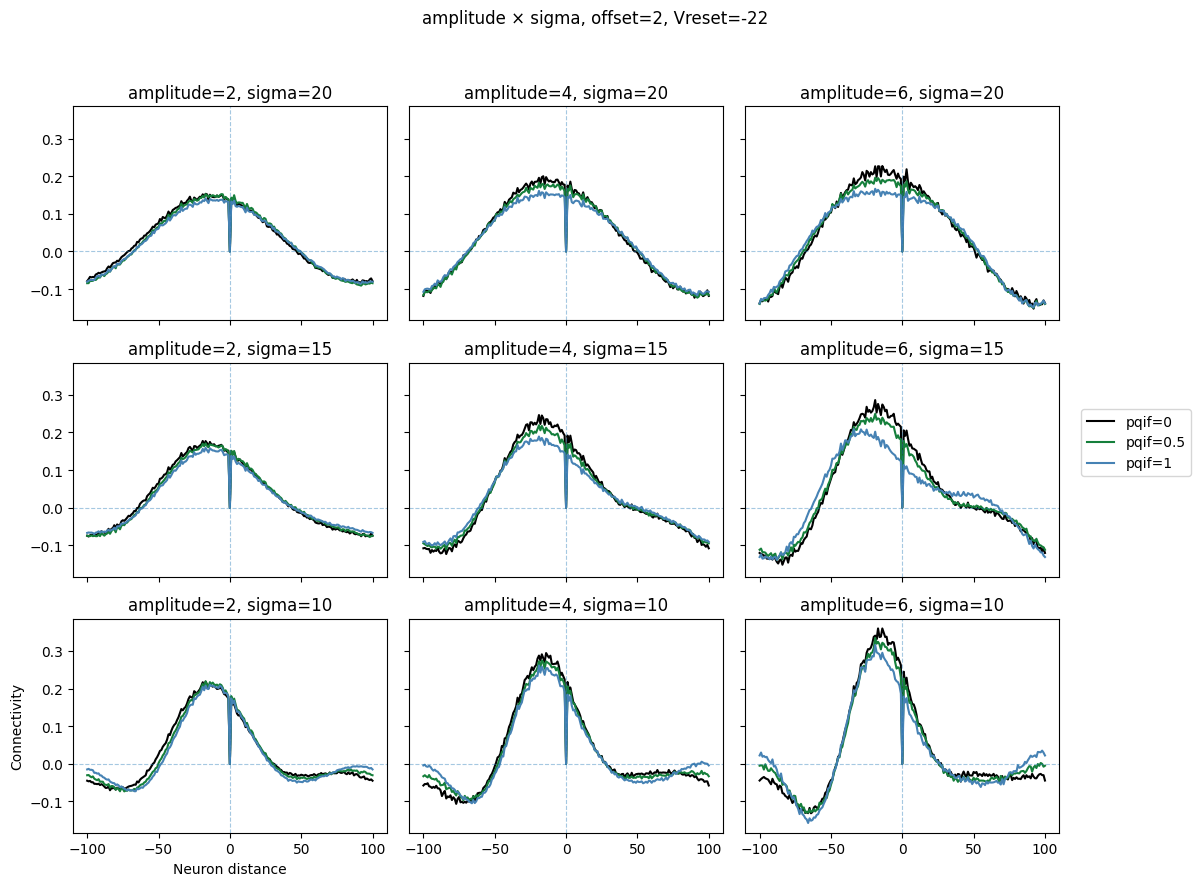

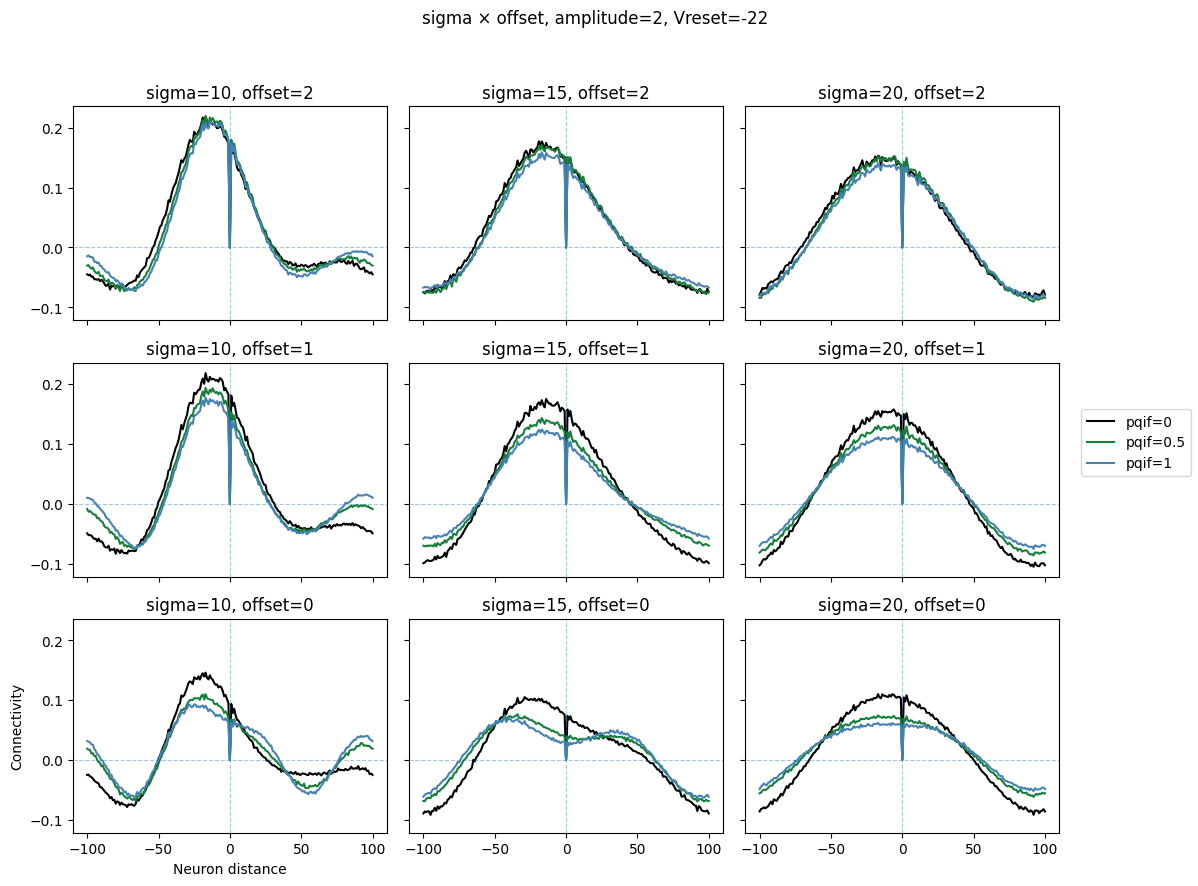

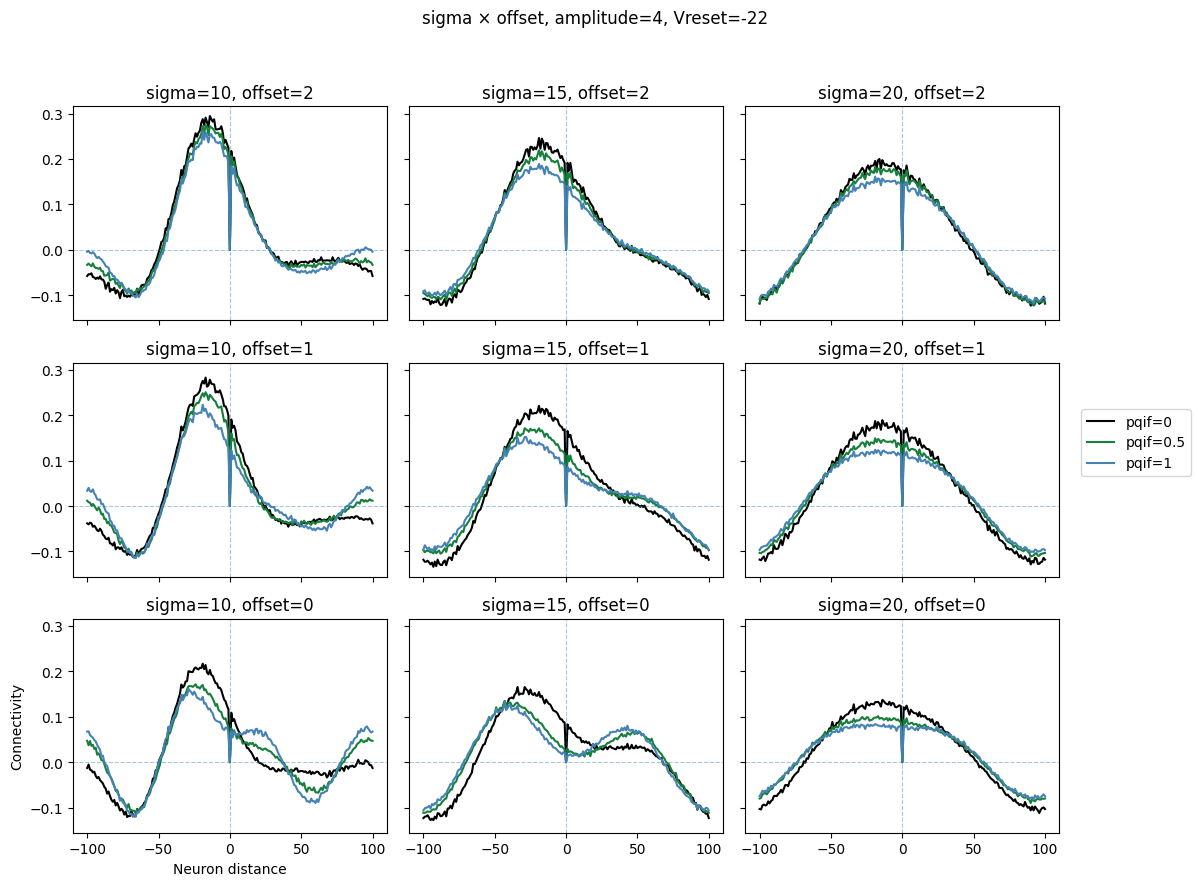

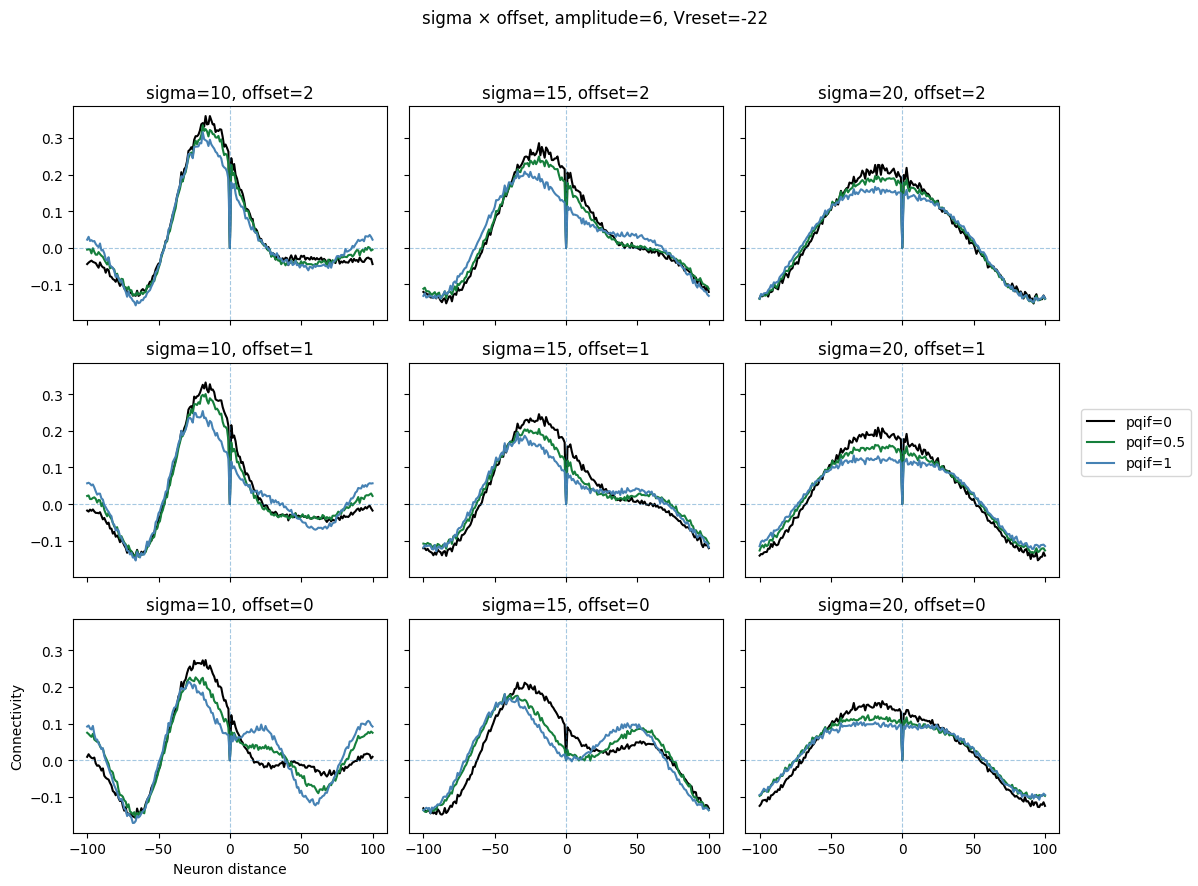

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import analysis_functions as af  # import all functions from analysis_functions.py

def plot_connectivity_grid(x_param, y_param, fixed_param, fixed_value, sim,):
    """
    Plots connectivity profiles where we specify which sequence parameter should be the big x- and y-axis,
    which sequence parameter should be fixed (and at which value), and which simulation number (determining
    vreset and gain) we do this for.
    """
    x_values = getattr(sequences, f"{x_param}s")
    y_values = getattr(sequences, f"{y_param}s")
    fig, axes = plt.subplots(len(y_values), len(x_values), figsize=(4*len(x_values), 3*len(y_values)), sharex=True, sharey=True, squeeze=False)

    for condition in sequences.sequence_conditions:

        if getattr(condition, fixed_param) != fixed_value: continue
        x = getattr(condition, x_param)
        y = getattr(condition, y_param)
        row = len(y_values)-1-y_values.index(y)
        col = x_values.index(x)

        target_params = pd.read_csv(sequences.path("target_parameters", condition=condition))
        sequence_position = target_params["sequence_position"].to_numpy(dtype=int)

        ax = axes[row, col]

        connectivity_path = sequences.path("connectivity", condition=condition, sim=sim,)

        for pqif in sequences.pqif_numbers:
            mean_W, _, _ = af.average_connectivity(sequences, condition, sim, pqif, sequences.seed_numbers)
            reordered_W = af.reorder_connectivity(mean_W, sequence_position)
            _, mean_J, std_J, neuron_distance = af.get_profile_from_matrix(reordered_W)
            ax.plot(neuron_distance, mean_J, color=color_map_pqif[pqif], label=f"pqif={pqif}")

        ax.set_title(f"{x_param}={x:g}, {y_param}={y:g}")
        ax.axvline(0, ls="--", lw=.8, alpha=.4)
        ax.axhline(0, ls="--", lw=.8, alpha=.4)
        

    fig.suptitle(f"{x_param} × {y_param}, {fixed_param}={fixed_value:g}, Vreset={sim.vreset}")
    axes[-1, 0].set_xlabel("Neuron distance")
    axes[-1, 0].set_ylabel("Connectivity")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right")
    fig.tight_layout(rect=[0, 0, .9, .95])
    plt.show()

for sim in sequences.sims:
    for sigma in sequences.sigmas: plot_connectivity_grid("amplitude", "offset", "sigma", sigma, sim)
    for offset in sequences.offsets: plot_connectivity_grid("amplitude", "sigma", "offset", offset, sim)
    for amplitude in sequences.amplitudes: plot_connectivity_grid("sigma", "offset", "amplitude", amplitude, sim)
